# Notebook 01 — Exploratory Data Analysis

**Project:** Federated learning for water quality classification (Master's thesis)  
**Dataset:** Comprehensive Surface Water Quality Monitoring Dataset
(Karim et al., *Scientific Data* 12:391, 2025) — 2.82M records across
five countries (Canada, China, England, Ireland, USA).

## Purpose

This notebook performs the exploratory analysis required to make every
methodological decision for the modeling stage:

- Section 1 — Per-country data inventory and schema.
- Section 2 — Feature distribution and imputation pattern detection.
- Section 3 — Data quality audit (duplicates, conflicts, invalids, outliers).
- Section 4 — Target variable analysis and leakage proof.
- Section 5 — Temporal coverage and split-boundary evaluation.
- Section 6 — Sequence-modeling feasibility under the proposed split.
- Section 7 — Cross-country heterogeneity (formal FL motivation).
- Section 8 — Federation feasibility synthesis.

## Outputs

All figures and tables are saved to `/kaggle/working/eda_outputs/`
(`figures/` in PNG + PDF, `tables/` in CSV). These artifacts are the
empirical evidence for Chapter 3 of the thesis and the rule book for
the deterministic preprocessing pipeline in `02_preprocess.ipynb`.

## Reproducibility

The notebook reads only from `/kaggle/input/...`; it never mutates the
raw source data. All randomness is seeded (`np.random.seed(42)`).
Every analytical decision is recorded as a table or figure on disk.

# Section 0 — Setup, reproducibility, and saving conventions
*****************************************

In [2]:
# ── Standard library ─────────────────────────────────────────────────────
import os
import json
import time
import warnings
from itertools import combinations

# ── Third-party ──────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew, kurtosis, ks_2samp
from scipy.spatial.distance import jensenshannon

# ── Configuration ────────────────────────────────────────────────────────
warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(42)

### Paths and output directories

In [3]:
DATA_ROOT   = "/kaggle/input/datasets/sarahaddouda/water-quality-index/Dataset"
OUTPUT_DIR  = "/kaggle/working/eda_outputs"
FIG_DIR     = os.path.join(OUTPUT_DIR, "figures")
TABLE_DIR   = os.path.join(OUTPUT_DIR, "tables")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)


COUNTRY_DIR  = os.path.join(DATA_ROOT, "Country-Wise Data")

COMBINED_DIR = os.path.join(DATA_ROOT, "Combined Data")
COMBINED_CSV = os.path.join(COMBINED_DIR, "Combined_dataset.csv")

### Country palette (one color per country)

In [4]:
COUNTRY_ORDER = ["Canada", "China", "England", "Ireland", "USA"]
COUNTRY_COLORS = {
    "Canada":  "#4C72B0",   # blue
    "China":   "#DD8452",   # orange
    "England": "#55A868",   # green
    "Ireland": "#C44E52",   # red
    "USA":     "#8172B2",   # purple
}

### Plot defaults (thesis-quality)

In [5]:
plt.rcParams.update({
    "figure.figsize":    (10, 5),
    "figure.dpi":        110,
    "savefig.dpi":       250,
    "savefig.bbox":      "tight",
    "font.size":         11,
    "axes.titlesize":    12,
    "axes.labelsize":    11,
    "axes.grid":         True,
    "grid.alpha":        0.25,
    "axes.spines.top":   False,
    "axes.spines.right": False,
})
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

In [6]:
def save_figure(name, fig=None, formats=("png", "pdf")):
    """Save a figure to FIG_DIR in PNG (for viewing) and PDF (for thesis)."""
    fig = fig or plt.gcf()
    for ext in formats:
        path = os.path.join(FIG_DIR, f"{name}.{ext}")
        fig.savefig(path)
    print(f"✓ saved figure: {name}.{'/'.join(formats)}")

def save_table(df, name):
    """Save a DataFrame to TABLE_DIR as CSV."""
    path = os.path.join(TABLE_DIR, f"{name}.csv")
    df.to_csv(path, index=False)
    print(f"✓ saved table : {name}.csv  ({df.shape[0]}×{df.shape[1]})")

print("Setup complete.")
print(f"Output dir: {OUTPUT_DIR}")

Setup complete.
Output dir: /kaggle/working/eda_outputs


# Section 1 — Dataset inventory
********************

In [7]:
client_files = {
    "Canada":  os.path.join(COUNTRY_DIR, "Canada_dataset.csv"),
    "China":   os.path.join(COUNTRY_DIR, "China_dataset.csv"),
    "England": os.path.join(COUNTRY_DIR, "England_dataset.csv"),
    "Ireland": os.path.join(COUNTRY_DIR, "Ireland_dataset.csv"),
    "USA":     os.path.join(COUNTRY_DIR, "USA_dataset.csv"),
}

dfs = {}
for country, path in client_files.items():
    df = pd.read_csv(path)
    dfs[country] = df
    print(f"{country:8s}  rows={df.shape[0]:>9,}  cols={df.shape[1]}")

Canada    rows=    3,949  cols=14
China     rows=   45,997  cols=14
England   rows=2,129,198  cols=14
Ireland   rows=  235,019  cols=14
USA       rows=  413,814  cols=14


In [8]:
rename_map = {
    "Ammonia (mg/l)":                   "NH3",
    "Biochemical Oxygen Demand (mg/l)": "BOD",
    "Dissolved Oxygen (mg/l)":          "DO",
    "Orthophosphate (mg/l)":            "PO4",
    "pH (ph units)":                    "pH",
    "Temperature (cel)":                "Temp",
    "Nitrogen (mg/l)":                  "Nitrogen",
    "Nitrate (mg/l)":                   "Nitrate",
    "Waterbody Type":                   "Waterbody_Type",
}

for country in dfs:
    dfs[country] = dfs[country].rename(columns=rename_map)
    dfs[country]["Date"] = pd.to_datetime(
        dfs[country]["Date"], format="%d-%m-%Y", errors="coerce"
    )

In [9]:
for country, df in dfs.items():
    n_bad = df["Date"].isna().sum()
    print(f"{country:8s}  unparseable dates: {n_bad}")

Canada    unparseable dates: 0
China     unparseable dates: 0
England   unparseable dates: 0
Ireland   unparseable dates: 0
USA       unparseable dates: 0


### Schema consistency check

In [10]:
schema_rows = []
for country, df in dfs.items():
    schema_rows.append({
        "Country": country,
        "N_columns": df.shape[1],
        "Columns": ", ".join(df.columns.tolist()),
    })
schema_df = pd.DataFrame(schema_rows)
save_table(schema_df, "01_schema_per_country")
schema_df

✓ saved table : 01_schema_per_country.csv  (5×3)


,Country,N_columns,Columns
0,Canada,14,"Country, Area, Waterbody_Type, Date, NH3, BOD,..."
1,China,14,"Country, Area, Waterbody_Type, Date, NH3, BOD,..."
2,England,14,"Country, Area, Waterbody_Type, Date, NH3, BOD,..."
3,Ireland,14,"Country, Area, Waterbody_Type, Date, NH3, BOD,..."
4,USA,14,"Country, Area, Waterbody_Type, Date, NH3, BOD,..."


### Inventory table

In [11]:
inventory_rows = []
for country in COUNTRY_ORDER:
    df = dfs[country]
    inventory_rows.append({
        "Country":          country,
        "Rows":             df.shape[0],
        "Columns":          df.shape[1],
        "Date_Min":         df["Date"].min(),
        "Date_Max":         df["Date"].max(),
        "Span_Years":       round((df["Date"].max() - df["Date"].min()).days / 365.25, 1),
        "Unique_Areas":     df["Area"].nunique(),
        "Waterbody_Types":  df["Waterbody_Type"].nunique(),
    })
inventory_df = pd.DataFrame(inventory_rows)
save_table(inventory_df, "01_inventory_per_country")
inventory_df

✓ saved table : 01_inventory_per_country.csv  (5×8)


,Country,Rows,Columns,Date_Min,Date_Max,Span_Years,Unique_Areas,Waterbody_Types
0,Canada,3949,14,1968-01-12,2021-02-15,53.1,2354,4
1,China,45997,14,2001-01-03,2017-12-16,17.0,1,1
2,England,2129198,14,2000-01-01,2023-10-23,23.8,48642,9
3,Ireland,235019,14,1940-11-10,2023-12-17,83.1,9737,4
4,USA,413814,14,1940-01-02,2023-07-26,83.6,955,3


### Row count visualization

✓ saved figure: 01_rows_per_country.png/pdf


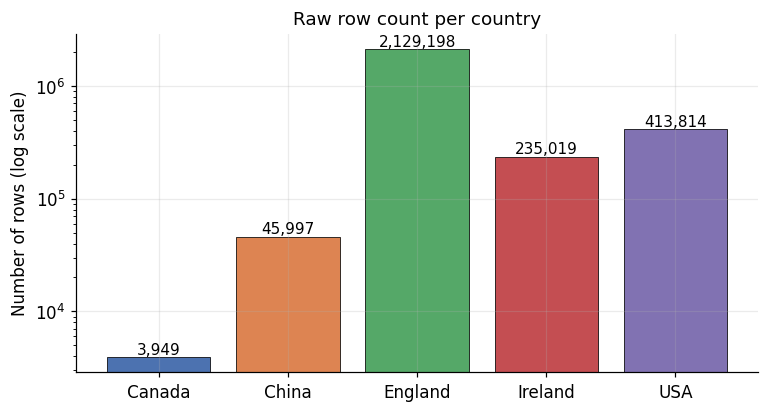

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
counts = [dfs[c].shape[0] for c in COUNTRY_ORDER]
colors = [COUNTRY_COLORS[c] for c in COUNTRY_ORDER]
bars = ax.bar(COUNTRY_ORDER, counts, color=colors, edgecolor="black", linewidth=0.5)

for bar, n in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"{n:,}", ha="center", va="bottom", fontsize=10)

ax.set_yscale("log")
ax.set_ylabel("Number of rows (log scale)")
ax.set_title("Raw row count per country")
save_figure("01_rows_per_country")
plt.show()

### Temporal coverage (Gantt-style chart)

✓ saved figure: 01_temporal_coverage_span.png/pdf


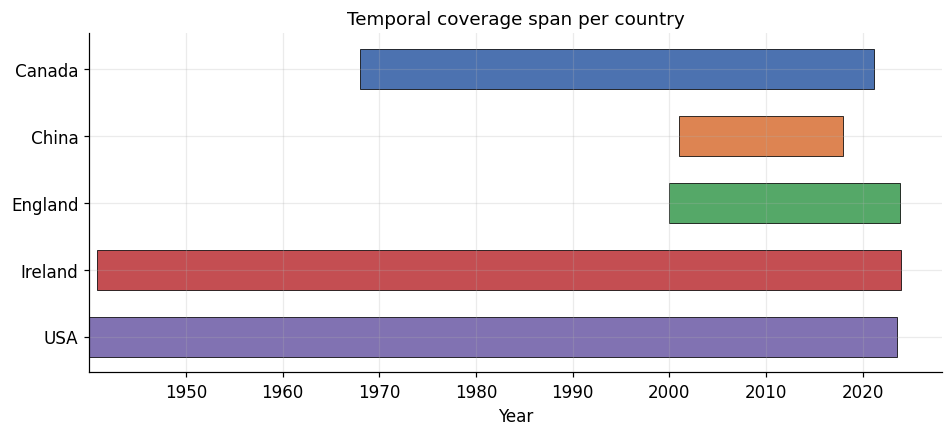

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
for i, country in enumerate(COUNTRY_ORDER):
    df = dfs[country]
    ax.barh(country,
            (df["Date"].max() - df["Date"].min()).days / 365.25,
            left=df["Date"].min().year + (df["Date"].min().dayofyear / 365.25),
            color=COUNTRY_COLORS[country], edgecolor="black", linewidth=0.5,
            height=0.6)

ax.set_xlabel("Year")
ax.set_title("Temporal coverage span per country")
ax.invert_yaxis()
save_figure("01_temporal_coverage_span")
plt.show()

# Section 2 — Feature distribution analysis
****************************
For each of the 8 monitoring parameters (NH3, BOD, DO, PO4, pH, Temp,
Nitrogen, Nitrate), we examine:

1. Per-country summary statistics (count, missing, quantiles, mean, std,
   skewness, kurtosis).
2. Per-country distribution shapes via boxplots and overlaid kernel
   density estimates.
3. Cross-country comparison to motivate the federated (non-IID) setting.

Note: this section operates on **raw** values; invalid measurements
(e.g. pH > 14, negative concentrations) are kept and will be quantified
in Section 3.

### Feature set and summary statistics

In [14]:
FEATURE_COLS = ["NH3", "BOD", "DO", "PO4", "pH", "Temp", "Nitrogen", "Nitrate"]

stat_rows = []
for country in COUNTRY_ORDER:
    df = dfs[country]
    n_total = len(df)
    for col in FEATURE_COLS:
        s = df[col].dropna()
        n = len(s)
        stat_rows.append({
            "Country":   country,
            "Parameter": col,
            "N":         n,
            "Missing_%": round(100 * (n_total - n) / n_total, 2),
            "Min":       s.min(),
            "Q1":        s.quantile(0.25),
            "Median":    s.quantile(0.50),
            "Q3":        s.quantile(0.75),
            "Max":       s.max(),
            "Mean":      s.mean(),
            "Std":       s.std(),
            "Skew":      skew(s) if n > 2 else np.nan,
            "Kurtosis":  kurtosis(s) if n > 3 else np.nan,
        })

feature_stats = pd.DataFrame(stat_rows)
# round numerical columns for display
num_cols = ["Min","Q1","Median","Q3","Max","Mean","Std","Skew","Kurtosis"]
feature_stats[num_cols] = feature_stats[num_cols].round(3)

save_table(feature_stats, "02_feature_stats_long")
feature_stats

✓ saved table : 02_feature_stats_long.csv  (40×13)


,Country,Parameter,N,Missing_%,Min,Q1,Median,Q3,Max,Mean,Std,Skew,Kurtosis
0,Canada,NH3,3949,0.0,0.000,0.050,0.100,0.196,63.836,0.847,3.620,6.329,51.528
1,Canada,BOD,3949,0.0,0.000,2.000,2.133,3.000,231.108,3.186,7.393,18.579,428.846
2,Canada,DO,3949,0.0,0.058,9.300,9.824,10.775,16.930,9.897,1.441,-1.279,5.893
3,Canada,PO4,3949,0.0,0.000,0.030,0.061,0.150,35.338,0.426,2.370,8.243,70.151
4,Canada,pH,3949,0.0,3.475,7.640,7.790,7.933,19.445,7.688,0.634,1.635,64.072
5,Canada,Temp,3949,0.0,0.000,10.172,12.000,14.600,89.000,12.421,4.078,1.843,32.686
6,Canada,Nitrogen,3949,0.0,0.000,0.400,0.400,0.400,41.784,0.679,1.392,10.279,213.944
7,Canada,Nitrate,3949,0.0,0.000,2.081,5.837,13.084,150.000,10.202,13.711,3.938,24.478
8,China,NH3,45997,0.0,0.005,0.024,0.046,0.100,10.000,0.101,0.321,14.344,256.313
9,China,BOD,45997,0.0,0.100,0.500,0.700,1.100,21.000,0.911,0.768,4.499,46.701


### At-a-glance pivot tables

In [15]:
# Pivot: median of each parameter across countries
pivot_median = feature_stats.pivot(index="Parameter", columns="Country", values="Median")[COUNTRY_ORDER]
save_table(pivot_median.reset_index(), "02_pivot_median")
print("\nMedian per parameter, per country:")
print(pivot_median)

# Pivot: skewness (high values reveal long-tailed parameters)
pivot_skew = feature_stats.pivot(index="Parameter", columns="Country", values="Skew")[COUNTRY_ORDER]
save_table(pivot_skew.reset_index(), "02_pivot_skew")
print("\nSkewness per parameter, per country (|skew|>1 = strongly skewed):")
print(pivot_skew.round(2))

# Pivot: missing fraction
pivot_missing = feature_stats.pivot(index="Parameter", columns="Country", values="Missing_%")[COUNTRY_ORDER]
save_table(pivot_missing.reset_index(), "02_pivot_missing")
print("\nMissing % per parameter, per country:")
print(pivot_missing)

✓ saved table : 02_pivot_median.csv  (8×6)

Median per parameter, per country:
Country    Canada   China  England  Ireland     USA
Parameter                                          
BOD         2.133   0.700    2.700    1.400   1.600
DO          9.824   7.600   10.200    9.090   9.870
NH3         0.100   0.046    0.098    0.038   0.021
Nitrate     5.837   0.077    4.500    1.300   0.900
Nitrogen    0.400   0.019    5.000    1.422   0.400
PO4         0.061   0.011    0.144    0.025   0.040
Temp       12.000  24.200   11.460   11.150  11.100
pH          7.790   8.000    7.780    7.800   7.800
✓ saved table : 02_pivot_skew.csv  (8×6)

Skewness per parameter, per country (|skew|>1 = strongly skewed):
Country    Canada  China  England  Ireland     USA
Parameter                                         
BOD         18.58   4.50     8.91    57.48   46.28
DO          -1.28  -0.02    -1.44    -0.21   -1.62
NH3          6.33  14.34    10.47    87.71  100.36
Nitrate      3.94   4.84     3.04    1

### Boxplots: per-parameter distribution per country

✓ saved figure: 02_boxplots_per_parameter.png/pdf


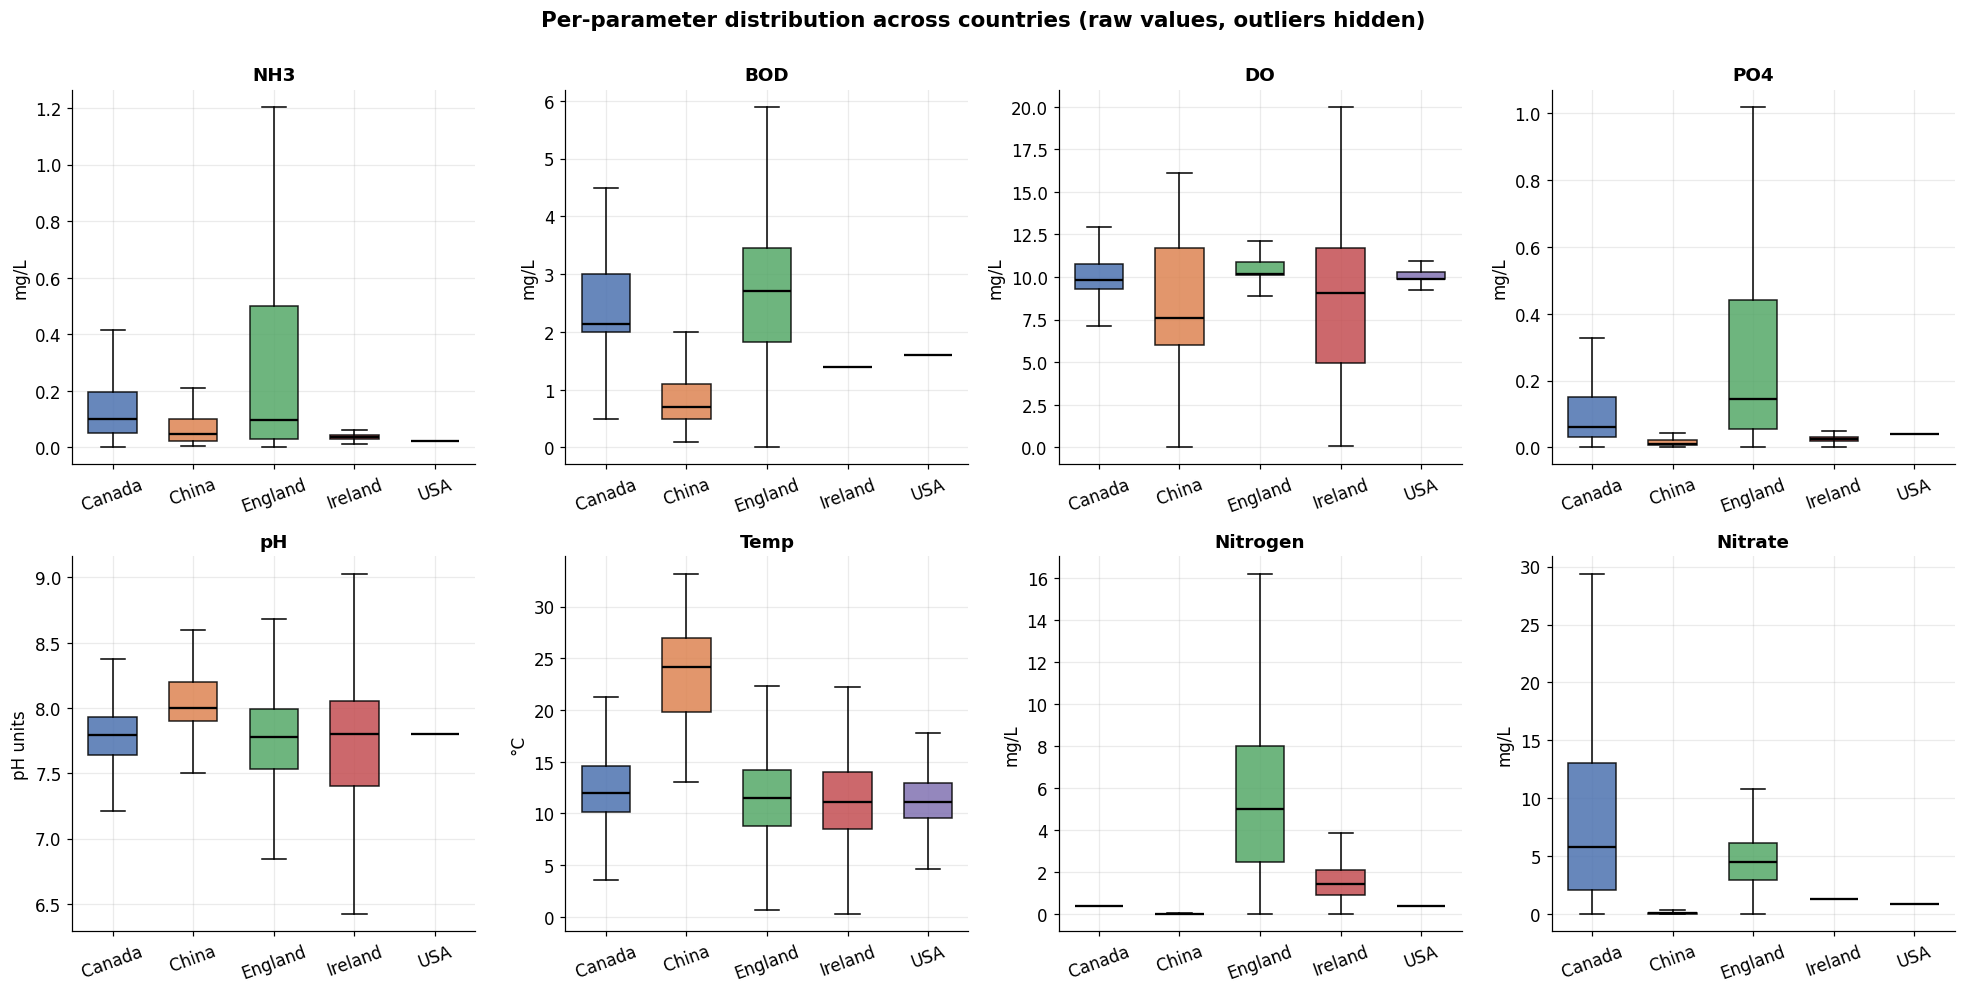

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
fig.suptitle("Per-parameter distribution across countries (raw values, outliers hidden)",
             fontsize=14, fontweight="bold", y=1.00)

for ax, col in zip(axes.flatten(), FEATURE_COLS):
    data = [dfs[c][col].dropna().values for c in COUNTRY_ORDER]
    bp = ax.boxplot(data,
                    tick_labels=COUNTRY_ORDER,
                    patch_artist=True,
                    showfliers=False,        # large datasets → flier dots dominate
                    widths=0.6,
                    medianprops=dict(color="black", linewidth=1.5))
    for patch, country in zip(bp["boxes"], COUNTRY_ORDER):
        patch.set_facecolor(COUNTRY_COLORS[country])
        patch.set_alpha(0.85)

    unit = "pH units" if col == "pH" else ("°C" if col == "Temp" else "mg/L")
    ax.set_title(col, fontweight="bold")
    ax.set_ylabel(unit)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
save_figure("02_boxplots_per_parameter")
plt.show()

✓ saved figure: 02_density_per_parameter.png/pdf


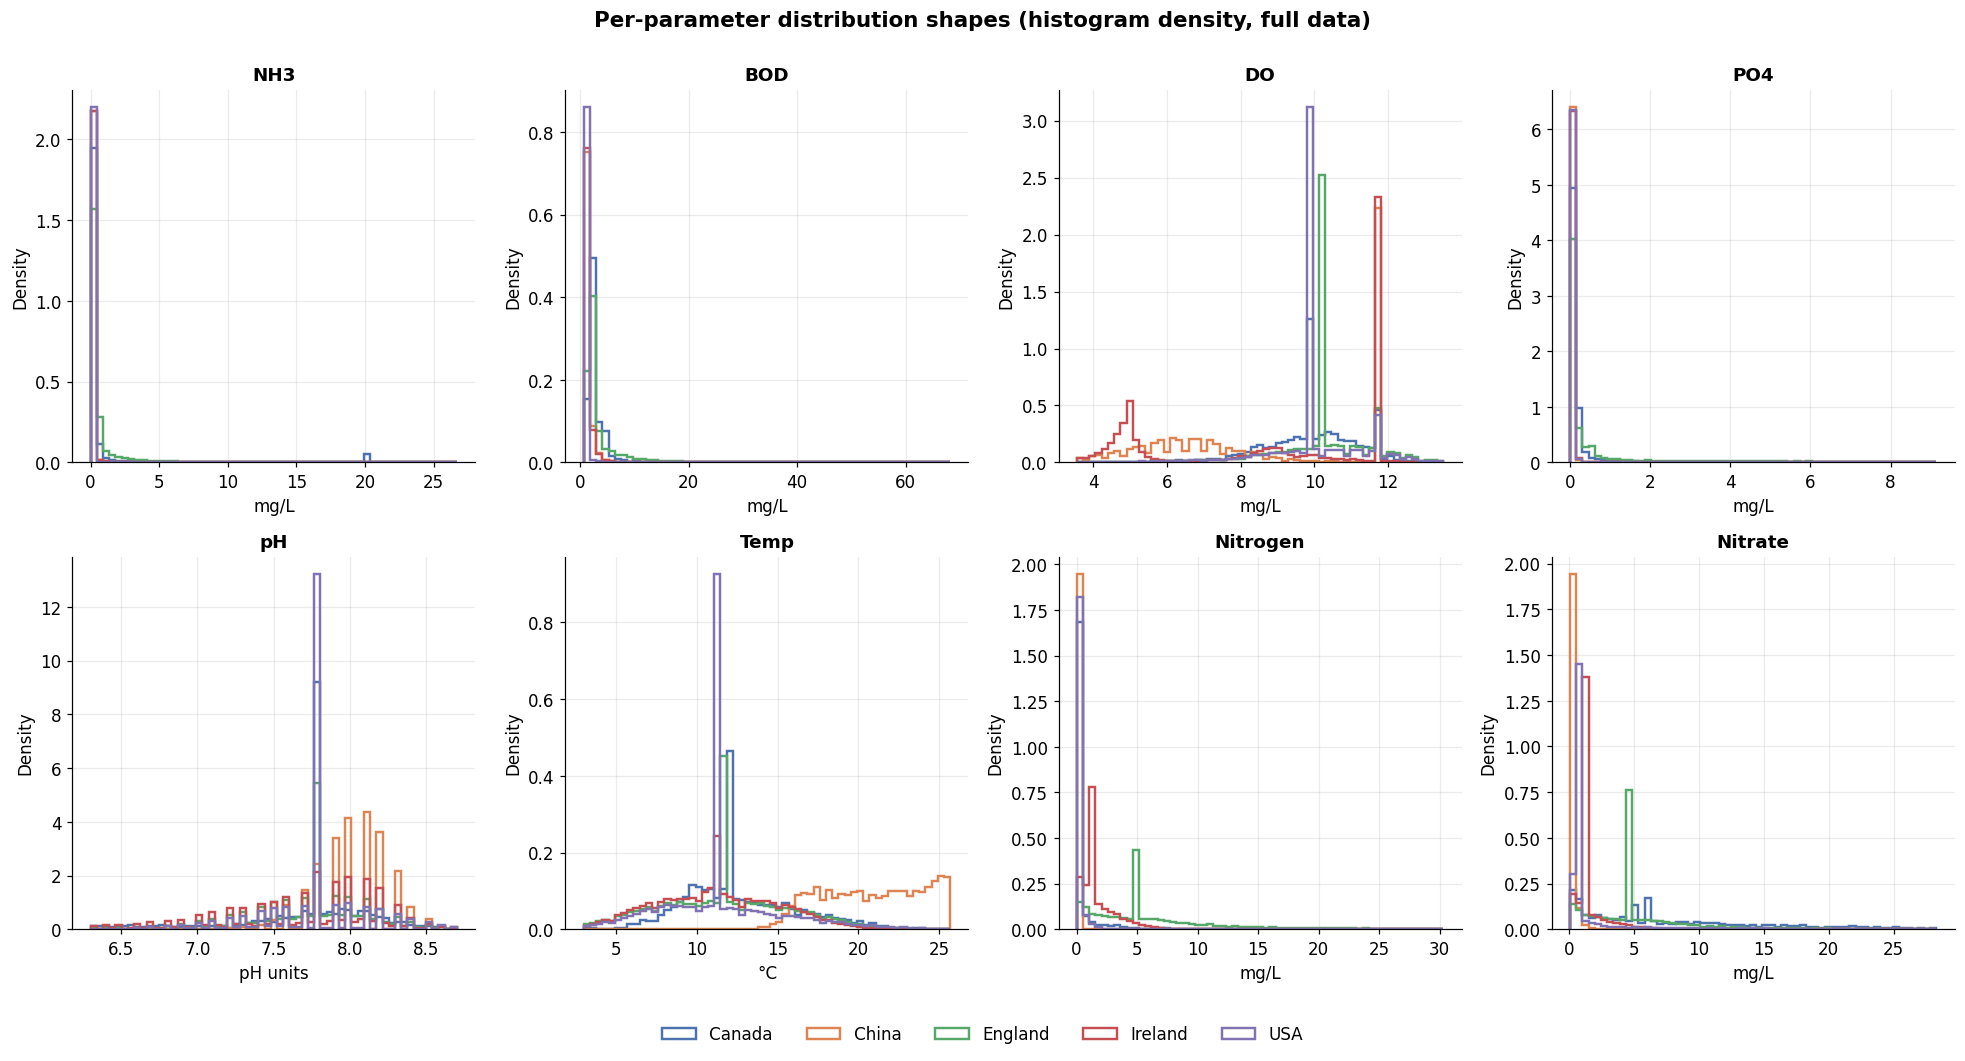

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
fig.suptitle("Per-parameter distribution shapes (histogram density, full data)",
             fontsize=14, fontweight="bold", y=1.00)

for ax, col in zip(axes.flatten(), FEATURE_COLS):
    # determine common x-range across countries (1st–99th percentile pooled)
    pooled = pd.concat([dfs[c][col].dropna() for c in COUNTRY_ORDER])
    lo, hi = pooled.quantile(0.01), pooled.quantile(0.99)
    bins = np.linspace(lo, hi, 60)

    for country in COUNTRY_ORDER:
        s = dfs[country][col].dropna()
        s = s[(s >= lo) & (s <= hi)]
        if len(s) < 30:
            continue
        ax.hist(s, bins=bins, density=True,
                histtype="step", linewidth=1.6,
                color=COUNTRY_COLORS[country], label=country)

    unit = "pH units" if col == "pH" else ("°C" if col == "Temp" else "mg/L")
    ax.set_title(col, fontweight="bold")
    ax.set_xlabel(unit)
    ax.set_ylabel("Density")

handles, labels = axes[0,0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5,
           bbox_to_anchor=(0.5, -0.01), frameon=False)
for ax in axes.flatten():
    if ax.get_legend(): ax.get_legend().remove()

plt.tight_layout()
save_figure("02_density_per_parameter")
plt.show()

### Coefficient of variation heatmap

✓ saved figure: 02_cv_heatmap.png/pdf


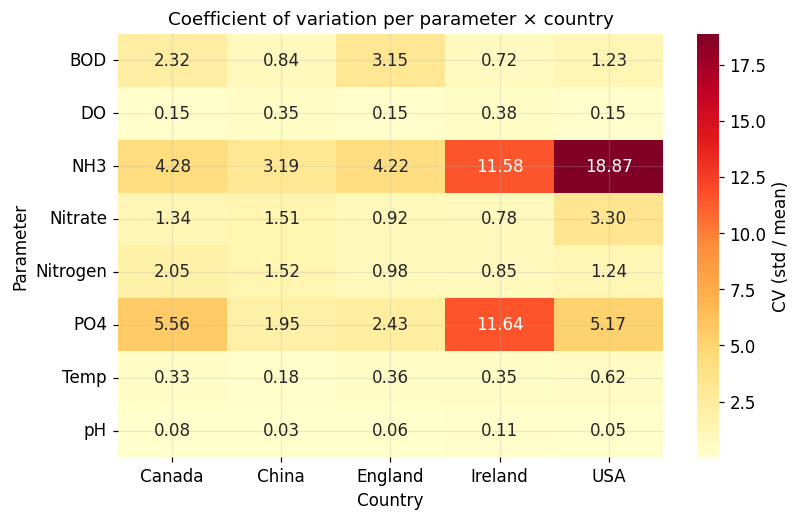

✓ saved table : 02_cv_pivot.csv  (8×6)


In [18]:
# CV = std / mean. Useful only when mean is meaningfully > 0.
cv_rows = []
for country in COUNTRY_ORDER:
    for col in FEATURE_COLS:
        s = dfs[country][col].dropna()
        m = s.mean()
        cv = s.std() / m if m > 1e-6 else np.nan
        cv_rows.append({"Country": country, "Parameter": col, "CV": cv})

cv_df = pd.DataFrame(cv_rows)
cv_pivot = cv_df.pivot(index="Parameter", columns="Country", values="CV")[COUNTRY_ORDER]

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(cv_pivot, annot=True, fmt=".2f", cmap="YlOrRd",
            cbar_kws={"label": "CV (std / mean)"}, ax=ax)
ax.set_title("Coefficient of variation per parameter × country")
save_figure("02_cv_heatmap")
plt.show()
save_table(cv_pivot.reset_index(), "02_cv_pivot")

## 2.4 Detection of pre-imputation in the source dataset

The dataset paper (Karim et al., 2025) states that missing values were
filled by country-wise median imputation. We verify this empirically.
If > 50% of records for a given (country, parameter) share a single
value — impossible for naturally-occurring continuous data — that
value is almost certainly the imputed country median.

In [19]:
# Quantify modal-value dominance per (country, parameter)
# If > ~50% of records share a single value, that's almost certainly pre-imputation.

mode_rows = []
for country in COUNTRY_ORDER:
    df = dfs[country]
    n = len(df)
    for col in FEATURE_COLS:
        s = df[col].dropna()
        if len(s) == 0:
            continue
        modal_value = s.mode().iloc[0]
        modal_count = (s == modal_value).sum()
        modal_pct = 100 * modal_count / len(s)
        mode_rows.append({
            "Country":      country,
            "Parameter":    col,
            "Modal_Value":  round(modal_value, 4),
            "Modal_Count":  int(modal_count),
            "Modal_%":      round(modal_pct, 1),
        })

mode_df = pd.DataFrame(mode_rows)
mode_pivot = mode_df.pivot(index="Parameter", columns="Country", values="Modal_%")[COUNTRY_ORDER]

save_table(mode_df,    "02_modal_value_long")
save_table(mode_pivot.reset_index(), "02_modal_pct_pivot")

print("Percentage of records with the modal value, per parameter × country:")
print(mode_pivot.round(1))
print("\n>>> Cells with Modal_% > 50 indicate pre-imputed or detection-limit-clipped data.")
mode_df

✓ saved table : 02_modal_value_long.csv  (40×5)
✓ saved table : 02_modal_pct_pivot.csv  (8×6)
Percentage of records with the modal value, per parameter × country:
Country    Canada  China  England  Ireland   USA
Parameter                                       
BOD          20.8   12.8     32.2     57.7  96.3
DO           17.6   36.6     41.8     37.6  50.3
NH3          12.3    3.4     24.3     39.4  88.3
Nitrate       5.7    8.8     33.6     62.2  62.4
Nitrogen     70.2   20.0     19.2     31.1  81.9
PO4          19.1    7.6     20.9     34.5  79.2
Temp         14.2    1.3     14.6      5.4  33.3
pH           33.9   17.7     17.2      7.8  52.9

>>> Cells with Modal_% > 50 indicate pre-imputed or detection-limit-clipped data.


,Country,Parameter,Modal_Value,Modal_Count,Modal_%
0,Canada,NH3,0.1000,485,12.3
1,Canada,BOD,2.1333,822,20.8
2,Canada,DO,9.8240,696,17.6
3,Canada,PO4,0.0610,754,19.1
4,Canada,pH,7.7900,1340,33.9
5,Canada,Temp,12.0000,559,14.2
6,Canada,Nitrogen,0.4000,2773,70.2
7,Canada,Nitrate,5.8368,227,5.7
8,China,NH3,0.0460,1568,3.4
9,China,BOD,0.7000,5872,12.8


## 2.5 Imputation severity audit (real-data percentage)

Under a conservative threshold of 30% modal dominance, we flag the
imputed value per (country, parameter) and compute the fraction of
records that are *not* at that value — i.e. the estimated non-modal fraction (proxy for imputation severity).

In [20]:
IMPUTATION_THRESHOLD_PCT = 30.0

# Build lookup: (country, parameter) -> imputed value (the modal/median)
imputed_value_map = {}
for _, row in mode_df.iterrows():
    if row["Modal_%"] > IMPUTATION_THRESHOLD_PCT:
        imputed_value_map[(row["Country"], row["Parameter"])] = row["Modal_Value"]

# Audit: count imputed-vs-real cells per (country, parameter)
audit_rows = []
for country in COUNTRY_ORDER:
    df = dfs[country]
    for col in FEATURE_COLS:
        n = len(df[col].dropna())
        imputed_value = imputed_value_map.get((country, col))
        if imputed_value is None:
            n_imputed = 0
        else:
            n_imputed = int(np.isclose(df[col], imputed_value, atol=1e-6,
                                        equal_nan=False).sum())
        n_real = n - n_imputed
        audit_rows.append({
            "Country":        country,
            "Parameter":      col,
            "Imputed_Value":  imputed_value if imputed_value is not None else None,
            "N_total":        n,
            "N_imputed":      n_imputed,
            "N_real":         n_real,
            "Non_modal_proxy_%":         round(100 * n_real / n, 1) if n > 0 else np.nan,
        })

imputation_audit = pd.DataFrame(audit_rows)
real_pct_pivot   = imputation_audit.pivot(
    index="Parameter", columns="Country", values="Non_modal_proxy_%"
)[COUNTRY_ORDER]

save_table(imputation_audit, "02_imputation_audit_long")
save_table(real_pct_pivot.reset_index(), "02_real_data_pct_pivot")

print(f"Imputation flagging threshold: modal % > {IMPUTATION_THRESHOLD_PCT}%")
print("\nEstimated non-modal % (proxy for imputation severity), per parameter × country:")
print(real_pct_pivot.round(1))

✓ saved table : 02_imputation_audit_long.csv  (40×7)
✓ saved table : 02_real_data_pct_pivot.csv  (8×6)
Imputation flagging threshold: modal % > 30.0%

Estimated non-modal % (proxy for imputation severity), per parameter × country:
Country    Canada  China  England  Ireland   USA
Parameter                                       
BOD         100.0  100.0     67.8     42.3   3.7
DO          100.0   63.4     58.2     62.4  49.7
NH3         100.0  100.0    100.0     60.6  11.7
Nitrate     100.0  100.0     66.4     37.8  37.6
Nitrogen     29.8  100.0    100.0     68.9  18.1
PO4         100.0  100.0    100.0     65.5  20.8
Temp        100.0  100.0    100.0    100.0  66.7
pH           66.1  100.0    100.0    100.0  47.1


✓ saved figure: 02_real_data_pct_heatmap.png/pdf


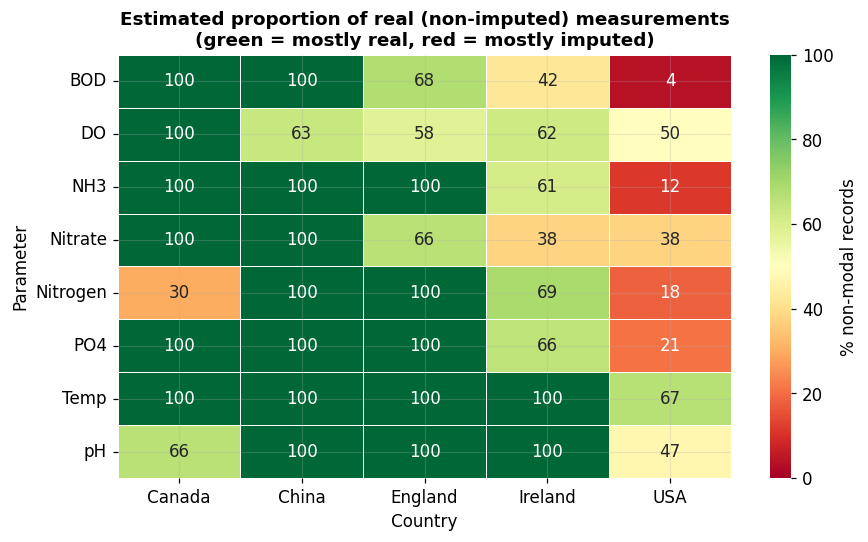

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(real_pct_pivot, annot=True, fmt=".0f",
            cmap="RdYlGn", vmin=0, vmax=100,
            cbar_kws={"label": "% non-modal records"},
            ax=ax, linewidths=0.5, linecolor="white")
ax.set_title("Estimated proportion of real (non-imputed) measurements\n"
             "(green = mostly real, red = mostly imputed)",
             fontsize=12, fontweight="bold")
save_figure("02_real_data_pct_heatmap")
plt.show()

# Section 3 — Data Quality Audit
*******************************************************************

We catalog data-integrity issues independent of the imputation question:
exact duplicates, conflicting site–date records, physically impossible values
(negative concentrations, pH outside [0, 14], implausible temperatures),
and outlier rates per country × parameter. The output of this section is
a rule book for `02_preprocess.ipynb`.

`site_id = Area + "__" + Waterbody_Type` is constructed here as a derived
column. Its limitation (multiple physical stations within one Area collapse
into one site_id) is a known constraint of the public dataset and will
be stated as such in the methodology chapter.

### Construct site_id

In [22]:
for country in COUNTRY_ORDER:
    dfs[country]["site_id"] = (
        dfs[country]["Area"].astype(str) + "__" +
        dfs[country]["Waterbody_Type"].astype(str)
    )

site_summary = pd.DataFrame([
    {
        "Country":        c,
        "Unique_sites":   dfs[c]["site_id"].nunique(),
        "Min_obs/site":   dfs[c].groupby("site_id").size().min(),
        "Median_obs/site": int(dfs[c].groupby("site_id").size().median()),
        "Max_obs/site":   dfs[c].groupby("site_id").size().max(),
    }
    for c in COUNTRY_ORDER
])
save_table(site_summary, "03_site_summary")
site_summary

✓ saved table : 03_site_summary.csv  (5×5)


,Country,Unique_sites,Min_obs/site,Median_obs/site,Max_obs/site
0,Canada,2354,1,1,100
1,China,1,45997,45997,45997
2,England,56317,1,9,2582
3,Ireland,9742,1,2,8459
4,USA,955,1,5,54281


## 3.1 Exact-duplicate detection

Exact duplicates (rows identical across all columns) almost always indicate
data-export errors at the compilation stage. They must be removed before
modelling. We count and report per country.

In [23]:
exact_dup_rows = []
for country in COUNTRY_ORDER:
    df = dfs[country]
    n_total = len(df)
    n_dup   = df.duplicated().sum()
    exact_dup_rows.append({
        "Country":     country,
        "Total_rows":  n_total,
        "Exact_dups":  int(n_dup),
        "Dup_%":       round(100 * n_dup / n_total, 2),
    })

exact_dup_df = pd.DataFrame(exact_dup_rows)
save_table(exact_dup_df, "03_exact_duplicates")
print("Exact-duplicate counts per country:")
print(exact_dup_df.to_string(index=False))

✓ saved table : 03_exact_duplicates.csv  (5×4)
Exact-duplicate counts per country:
Country  Total_rows  Exact_dups  Dup_%
 Canada        3949          55   1.39
  China       45997          20   0.04
England     2129198        1301   0.06
Ireland      235019          26   0.01
    USA      413814        8569   2.07


## 3.2 Same-`(site_id, Date)` repeated-record detection

Multiple records with the same constructed `(site_id, Date)` do not necessarily indicate an error. Since `site_id` is constructed from `Area` and `Waterbody_Type`, several real monitoring stations or repeated samples may be grouped under the same identifier. Therefore, same-site/date repetitions may represent repeated sampling, multiple stations collapsed into one constructed site, or compilation duplication.

For this reason, these cases are treated as aggregation cases rather than automatically as errors. We distinguish between:

- `Concordant`: same `(site_id, Date)` with identical feature values across rows.
- `Conflicting`: same `(site_id, Date)` with different feature values across rows.

In [24]:
conflict_rows = []
for country in COUNTRY_ORDER:
    df = dfs[country]
    grouped = df.groupby(["site_id", "Date"])
    n_groups = grouped.ngroups

    # how many groups have >1 row?
    multi_row = (grouped.size() > 1)
    n_multi   = int(multi_row.sum())

    # of multi-row groups, how many have ANY disagreement on FEATURE_COLS?
    if n_multi > 0:
        # nunique > 1 in any feature column → conflicting
        conflicts = grouped[FEATURE_COLS].nunique().gt(1).any(axis=1)
        n_conflict = int(conflicts.sum())
    else:
        n_conflict = 0

    conflict_rows.append({
        "Country":            country,
        "Unique_(site,Date)": n_groups,
        "Multi_row_groups":   n_multi,
        "Concordant":         n_multi - n_conflict,
        "Conflicting":        n_conflict,
        "Conflict_%_of_groups": round(100 * n_conflict / n_groups, 2) if n_groups else 0,
    })

conflict_df = pd.DataFrame(conflict_rows)
save_table(conflict_df, "03_site_date_conflicts")
print("Same-(site_id, Date) duplicates and conflicts per country:")
print(conflict_df.to_string(index=False))

✓ saved table : 03_site_date_conflicts.csv  (5×6)
Same-(site_id, Date) duplicates and conflicts per country:
Country  Unique_(site,Date)  Multi_row_groups  Concordant  Conflicting  Conflict_%_of_groups
 Canada                3492               313          55          258                  7.39
  China                2250              2250           0         2250                100.00
England             2053605             34852         331        34521                  1.68
Ireland              227063              1572           6         1566                  0.69
    USA              134864             65608         242        65366                 48.47


## 3.3 Physically impossible values

Any value outside the physically valid range is a recording error
regardless of whether the dataset was imputed. The accepted ranges:

| Parameter | Lower | Upper | Source |
|-----------|-------|-------|--------|
| NH3, BOD, DO, PO4, Nitrogen, Nitrate | 0 | none | Concentrations cannot be negative |
| pH | 0 | 14 | Definition of pH |
| Temperature | -2 | 45 °C | Plausible surface-water range; allows slightly sub-zero readings for saline, estuarine, or marine waters; values above 45 °C are treated as implausible in this monitoring context |Rows containing impossible values will be discarded in `02_preprocess.ipynb`.

In [25]:
# Validity rules: (lower, upper) — None means unbounded on that side
VALIDITY_RULES = {
    "NH3":      (0,    None),
    "BOD":      (0,    None),
    "DO":       (0,    None),
    "PO4":      (0,    None),
    "Nitrogen": (0,    None),
    "Nitrate":  (0,    None),
    "pH":       (0,    14),
    "Temp":     (-2,   45),
}

invalid_rows = []
for country in COUNTRY_ORDER:
    df = dfs[country]
    n_total = len(df)
    for col, (lo, hi) in VALIDITY_RULES.items():
        s = df[col]
        mask = pd.Series(False, index=df.index)
        if lo is not None:
            mask |= (s < lo)
        if hi is not None:
            mask |= (s > hi)
        n_invalid = int(mask.sum())
        invalid_rows.append({
            "Country":   country,
            "Parameter": col,
            "Lower":     lo,
            "Upper":     hi,
            "N_invalid": n_invalid,
            "Invalid_%": round(100 * n_invalid / n_total, 3) if n_total else 0,
        })

invalid_df = pd.DataFrame(invalid_rows)
invalid_pivot = invalid_df.pivot(index="Parameter",
                                 columns="Country",
                                 values="Invalid_%")[COUNTRY_ORDER]
save_table(invalid_df,    "03_invalid_values_long")
save_table(invalid_pivot.reset_index(), "03_invalid_pct_pivot")

print("Invalid-value % per parameter × country:")
print(invalid_pivot.round(3))

✓ saved table : 03_invalid_values_long.csv  (40×6)
✓ saved table : 03_invalid_pct_pivot.csv  (8×6)
Invalid-value % per parameter × country:
Country    Canada  China  England  Ireland    USA
Parameter                                        
BOD         0.000    0.0    0.000    0.001  0.000
DO          0.000    0.0    0.000    0.000  0.000
NH3         0.000    0.0    0.000    0.001  0.000
Nitrate     0.000    0.0    0.000    0.000  0.000
Nitrogen    0.000    0.0    0.000    0.000  0.000
PO4         0.000    0.0    0.000    0.004  0.000
Temp        0.025    0.0    0.004    0.052  1.599
pH          0.051    0.0    0.000    0.213  0.000


### Invalid value heatmap

✓ saved figure: 03_invalid_values_heatmap.png/pdf


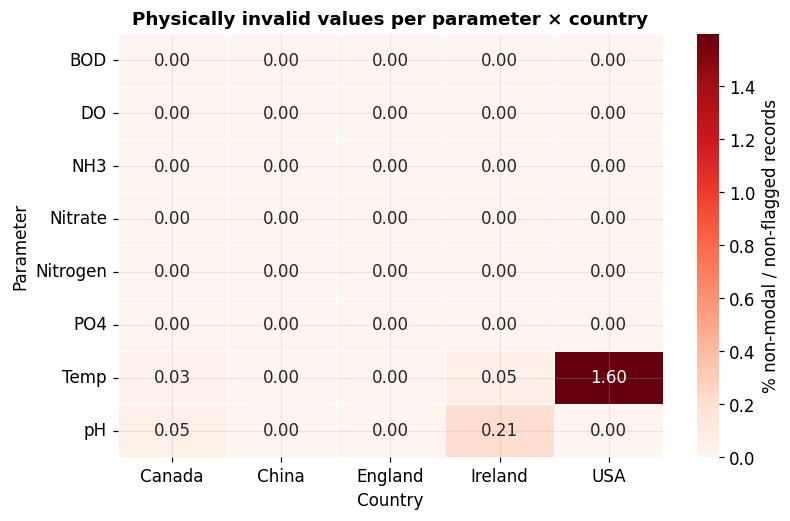

In [26]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(invalid_pivot, annot=True, fmt=".2f", cmap="Reds",
            cbar_kws={"label": "% non-modal / non-flagged records"},
            ax=ax, linewidths=0.5, linecolor="white")
ax.set_title("Physically invalid values per parameter × country",
             fontweight="bold")
save_figure("03_invalid_values_heatmap")
plt.show()

## 3.4 Outlier rate (IQR-fence based, raw counts only)

We count outliers per country × parameter using the standard 1.5 × IQR
fence rule (Tukey 1977). We do not remove them here — that is a
preprocessing decision, not an EDA finding. The purpose is to see
where the heaviest tails are, by country.

✓ saved table : 03_outliers_long.csv  (40×6)
✓ saved table : 03_outlier_pct_pivot.csv  (8×6)
✓ saved figure: 03_outlier_heatmap.png/pdf


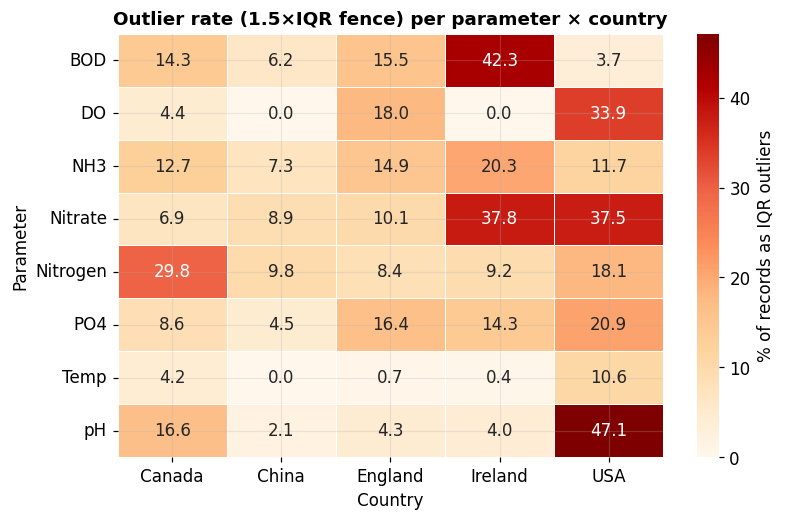


Outlier % per parameter × country:
Country    Canada  China  England  Ireland    USA
Parameter                                        
BOD         14.33   6.17    15.47    42.33   3.68
DO           4.43   0.00    18.02     0.00  33.86
NH3         12.74   7.34    14.91    20.34  11.71
Nitrate      6.89   8.93    10.12    37.83  37.55
Nitrogen    29.78   9.83     8.43     9.24  18.13
PO4          8.58   4.46    16.44    14.31  20.85
Temp         4.23   0.00     0.69     0.40  10.61
pH          16.59   2.15     4.28     3.97  47.11


In [27]:
outlier_rows = []
for country in COUNTRY_ORDER:
    df = dfs[country]
    n_total = len(df)
    for col in FEATURE_COLS:
        s = df[col].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = int(((s < lo) | (s > hi)).sum())
        outlier_rows.append({
            "Country":   country,
            "Parameter": col,
            "Lower":     round(lo, 4),
            "Upper":     round(hi, 4),
            "N_outliers": n_out,
            "Outlier_%": round(100 * n_out / n_total, 2),
        })

outlier_df = pd.DataFrame(outlier_rows)
outlier_pivot = outlier_df.pivot(index="Parameter",
                                 columns="Country",
                                 values="Outlier_%")[COUNTRY_ORDER]
save_table(outlier_df,    "03_outliers_long")
save_table(outlier_pivot.reset_index(), "03_outlier_pct_pivot")

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(outlier_pivot, annot=True, fmt=".1f", cmap="OrRd",
            cbar_kws={"label": "% of records as IQR outliers"},
            ax=ax, linewidths=0.5, linecolor="white")
ax.set_title("Outlier rate (1.5×IQR fence) per parameter × country",
             fontweight="bold")
save_figure("03_outlier_heatmap")
plt.show()

print("\nOutlier % per parameter × country:")
print(outlier_pivot.round(2))

## 3.5 Quality summary

A single per-country row showing what `02_preprocess.ipynb` will need
to handle. This table goes directly into the methodology chapter.

### Per-country quality summary

In [28]:
summary_rows = []
for country in COUNTRY_ORDER:
    df    = dfs[country]
    n     = len(df)
    n_dup = exact_dup_df.set_index("Country").loc[country, "Exact_dups"]
    n_conf = conflict_df.set_index("Country").loc[country, "Conflicting"]
    n_inv = invalid_df[invalid_df["Country"] == country]["N_invalid"].sum()
    avg_outlier_pct = outlier_df[outlier_df["Country"] == country]["Outlier_%"].mean()
    summary_rows.append({
        "Country":              country,
        "Total_rows":           n,
        "Exact_duplicates":     int(n_dup),
        "Conflicting_(site,Date)": int(n_conf),
        "Invalid_value_cells":   int(n_inv),
        "Avg_outlier_%":        round(avg_outlier_pct, 2),
    })

quality_summary = pd.DataFrame(summary_rows)
save_table(quality_summary, "03_quality_summary")
print("Per-country data quality summary:")
print(quality_summary.to_string(index=False))

✓ saved table : 03_quality_summary.csv  (5×6)
Per-country data quality summary:
Country  Total_rows  Exact_duplicates  Conflicting_(site,Date)  Invalid_value_cells  Avg_outlier_%
 Canada        3949                55                      258                    3          12.20
  China       45997                20                     2250                    0           4.86
England     2129198              1301                    34521                   80          11.04
Ireland      235019                26                     1566                  638          16.05
    USA      413814              8569                    65366                 6617          22.94


# Section 4 — Target variable analysis
***********************************************************
We characterize the prediction target `CCME_WQI` (5-class water quality
classification under the CCME WQI model) on three dimensions:

1. **Class distribution per country** — quantifies class imbalance,
   which determines whether class-weighted loss or resampling is needed
   in the modeling stage.
2. **Determinism of `CCME_Values → CCME_WQI`** — empirically confirms
   that the continuous score `CCME_Values` is a closed-form function
   of the chemical features, and that including it among model inputs
   would constitute target leakage.
3. **Class proportions over time** — checks whether the label
   distribution is stationary across the period covered by each
   country, informing the train / validation / test split.

## 4.1 Class distribution per country

The CCME WQI defines five classes: **Excellent (95–100)**, **Good (80–94)**,
**Fair (65–79)**, **Marginal (45–64)**, **Poor (0–44)**.

A country whose data is dominated by one or two classes presents
a class-imbalance problem; if the imbalance pattern *differs* across
countries, the federated learning setting becomes non-IID on the label
distribution as well as on the feature distribution.

In [29]:
# Standard CCME class colours — traffic-light progression
CCME_CLASS_ORDER = ["Excellent", "Good", "Fair", "Marginal", "Poor"]
CCME_CLASS_COLORS = {
    "Excellent": "#1a9850",
    "Good":      "#a6d96a",
    "Fair":      "#fee08b",
    "Marginal":  "#fdae61",
    "Poor":      "#d73027",
}

# Per-country, per-class counts and percentages
class_rows = []
for country in COUNTRY_ORDER:
    df = dfs[country]
    n_total = len(df)
    counts = df["CCME_WQI"].value_counts()
    for cls in CCME_CLASS_ORDER:
        n = int(counts.get(cls, 0))
        class_rows.append({
            "Country":  country,
            "Class":    cls,
            "Count":    n,
            "Percent":  round(100 * n / n_total, 2) if n_total else 0,
        })

class_dist = pd.DataFrame(class_rows)
class_dist_pivot = class_dist.pivot(
    index="Class", columns="Country", values="Percent"
).reindex(CCME_CLASS_ORDER)[COUNTRY_ORDER]

save_table(class_dist,                       "04_class_distribution_long")
save_table(class_dist_pivot.reset_index(),   "04_class_distribution_pivot")

print("Class distribution (%) per country:")
print(class_dist_pivot.round(2))

✓ saved table : 04_class_distribution_long.csv  (25×4)
✓ saved table : 04_class_distribution_pivot.csv  (5×6)
Class distribution (%) per country:
Country    Canada  China  England  Ireland    USA
Class                                            
Excellent   35.48  54.60    20.93    84.24  84.74
Good        52.19  44.40    43.18    14.07  14.20
Fair         5.93   0.73    14.71     0.69   0.58
Marginal     4.81   0.26    15.29     0.39   0.46
Poor         1.60   0.00     5.89     0.61   0.02


### Stacked-bar visualization

✓ saved figure: 04_class_distribution_stacked.png/pdf


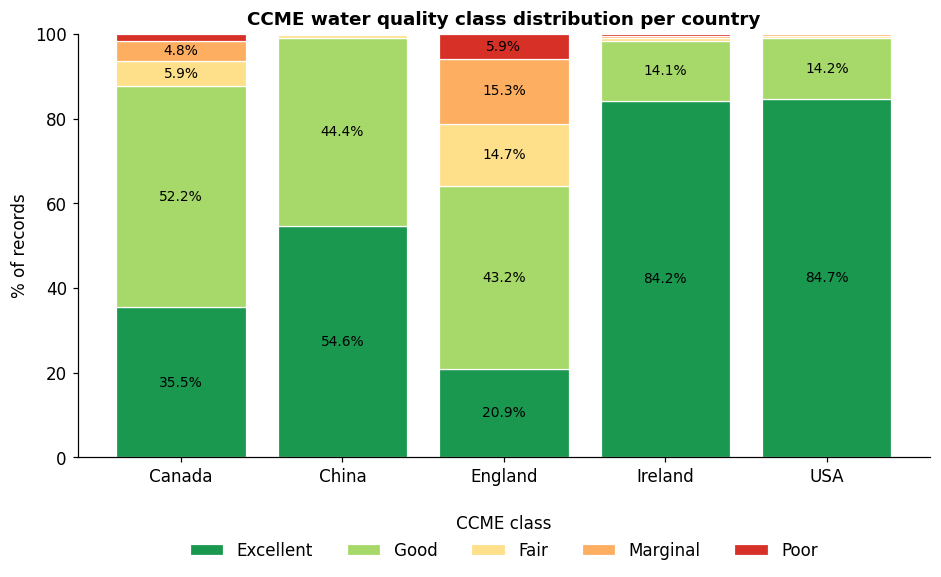

In [30]:
fig, ax = plt.subplots(figsize=(10, 5))
bottom = np.zeros(len(COUNTRY_ORDER))

for cls in CCME_CLASS_ORDER:
    values = [class_dist_pivot.loc[cls, c] for c in COUNTRY_ORDER]
    bars = ax.bar(COUNTRY_ORDER, values, bottom=bottom,
                  color=CCME_CLASS_COLORS[cls],
                  edgecolor="white", linewidth=0.8, label=cls)
    # Annotate slices ≥ 3% with the percentage
    for bar, v, b in zip(bars, values, bottom):
        if v >= 3:
            ax.text(bar.get_x() + bar.get_width()/2, b + v/2,
                    f"{v:.1f}%", ha="center", va="center",
                    fontsize=9, color="black")
    bottom += np.array(values)

ax.set_ylabel("% of records")
ax.set_ylim(0, 100)
ax.set_title("CCME water quality class distribution per country",
             fontweight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.10),
          ncol=5, frameon=False, title="CCME class")
ax.grid(False)
save_figure("04_class_distribution_stacked")
plt.show()

## 4.2 Determinism of `CCME_Values → CCME_WQI`

The dataset paper (Karim et al., 2025) computes `CCME_Values` from the
eight chemical parameters using the CCME closed-form formula, then
assigns `CCME_WQI` by thresholding `CCME_Values`. By construction the
mapping `CCME_Values → CCME_WQI` is therefore deterministic.

We verify this empirically by checking, for each country, whether any
single value of `CCME_Values` is associated with more than one
`CCME_WQI` class. If the answer is "zero" for every country, we have
confirmed that including `CCME_Values` as a feature would constitute
target leakage and it must be excluded from the model input.

### Determinism check

In [31]:
det_rows = []
for country in COUNTRY_ORDER:
    df = dfs[country]
    classes_per_value = df.groupby("CCME_Values")["CCME_WQI"].nunique()
    n_unique_values = len(classes_per_value)
    n_ambiguous     = int((classes_per_value > 1).sum())
    det_rows.append({
        "Country":             country,
        "Unique_CCME_Values":  n_unique_values,
        "Ambiguous_values":    n_ambiguous,
        "Deterministic":       (n_ambiguous == 0),
    })

det_df = pd.DataFrame(det_rows)
save_table(det_df, "04_ccme_values_determinism")
print("Determinism check — does CCME_Values uniquely determine CCME_WQI?")
print(det_df.to_string(index=False))

# Empirical CCME class boundaries (from the data, per country)
boundary_rows = []
for country in COUNTRY_ORDER:
    df = dfs[country]
    for cls in CCME_CLASS_ORDER:
        sub = df[df["CCME_WQI"] == cls]
        if len(sub) == 0:
            continue
        boundary_rows.append({
            "Country":            country,
            "Class":              cls,
            "Min_CCME_Values":    round(sub["CCME_Values"].min(), 4),
            "Max_CCME_Values":    round(sub["CCME_Values"].max(), 4),
            "N_records":          len(sub),
        })
boundary_df = pd.DataFrame(boundary_rows)
save_table(boundary_df, "04_ccme_class_boundaries")
print("\nEmpirical CCME class boundaries per country:")
print(boundary_df.to_string(index=False))

✓ saved table : 04_ccme_values_determinism.csv  (5×4)
Determinism check — does CCME_Values uniquely determine CCME_WQI?
Country  Unique_CCME_Values  Ambiguous_values  Deterministic
 Canada                1290                 0           True
  China                 977                 0           True
England              216154                 0           True
Ireland                5344                 0           True
    USA                4147                 0           True
✓ saved table : 04_ccme_class_boundaries.csv  (24×5)

Empirical CCME class boundaries per country:
Country     Class  Min_CCME_Values  Max_CCME_Values  N_records
 Canada Excellent         100.0000         100.0000       1401
 Canada      Good          80.2009          93.1957       2061
 Canada      Fair          65.2151          79.9942        234
 Canada  Marginal          45.3370          64.8435        190
 Canada      Poor          37.6592          44.8579         63
  China Excellent         100.0000   

### Visualization of the deterministic mapping

✓ saved figure: 04_ccme_values_to_class.png/pdf


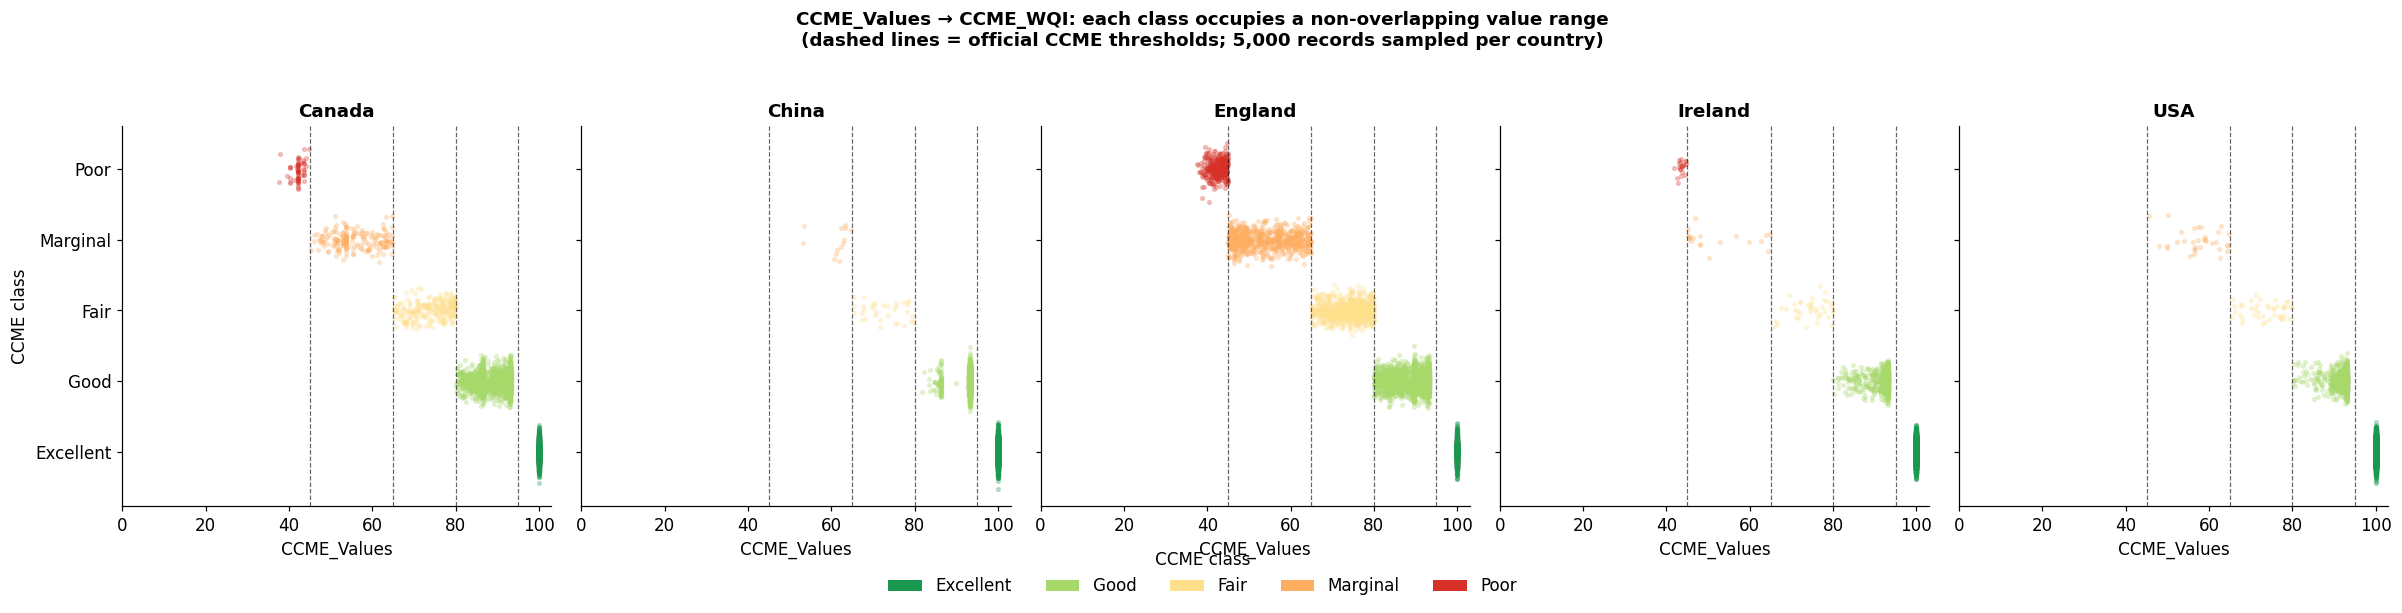

In [32]:
fig, axes = plt.subplots(1, 5, figsize=(22, 5), sharey=True)
fig.suptitle(
    "CCME_Values → CCME_WQI: each class occupies a non-overlapping value range\n"
    "(dashed lines = official CCME thresholds; 5,000 records sampled per country)",
    fontsize=12, fontweight="bold", y=1.03
)

N_SAMPLE = 5_000
CLASS_Y  = {cls: i for i, cls in enumerate(CCME_CLASS_ORDER)}  # Excellent=0 ... Poor=4
THRESHOLDS = [45, 65, 80, 95]

rng = np.random.default_rng(42)

for ax, country in zip(axes, COUNTRY_ORDER):
    df     = dfs[country]
    sample = df.sample(min(N_SAMPLE, len(df)), random_state=42)

    for cls in CCME_CLASS_ORDER:
        sub = sample[sample["CCME_WQI"] == cls]
        if len(sub) == 0:
            continue
        y_center = CLASS_Y[cls]
        y_jitter = rng.normal(y_center, 0.12, size=len(sub))
        ax.scatter(sub["CCME_Values"], y_jitter,
                   c=CCME_CLASS_COLORS[cls],
                   alpha=0.25, s=6, rasterized=True)

    # CCME threshold boundaries
    for thresh in THRESHOLDS:
        ax.axvline(thresh, color="black", linewidth=0.8,
                   linestyle="--", alpha=0.6)

    ax.set_title(country, fontweight="bold")
    ax.set_xlabel("CCME_Values")
    ax.set_xlim(0, 103)
    ax.set_yticks(list(CLASS_Y.values()))
    ax.set_yticklabels(list(CLASS_Y.keys()))
    ax.grid(False)

axes[0].set_ylabel("CCME class")

# shared legend patches
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=CCME_CLASS_COLORS[c], label=c) for c in CCME_CLASS_ORDER
]
fig.legend(handles=legend_handles, loc="lower center", ncol=5,
           bbox_to_anchor=(0.5, -0.06), frameon=False, title="CCME class")

plt.tight_layout()
save_figure("04_ccme_values_to_class")   # overwrites the old file
plt.show()

## 4.3 Class proportions over time

We compute the per-year proportion of each class within each country.
A stationary distribution means train/val/test splits across years
will not introduce label-shift bias. A drifting distribution means
the test period (e.g., 2020–2023) may have different class proportions
than the training period — a phenomenon to acknowledge in the results
chapter.

This analysis is performed on raw years; we do not yet apply monthly
resampling, which is a preprocessing step deferred to `02_preprocess.ipynb`.

### Annual class-proportion chart

✓ saved figure: 04_class_proportions_over_time.png/pdf


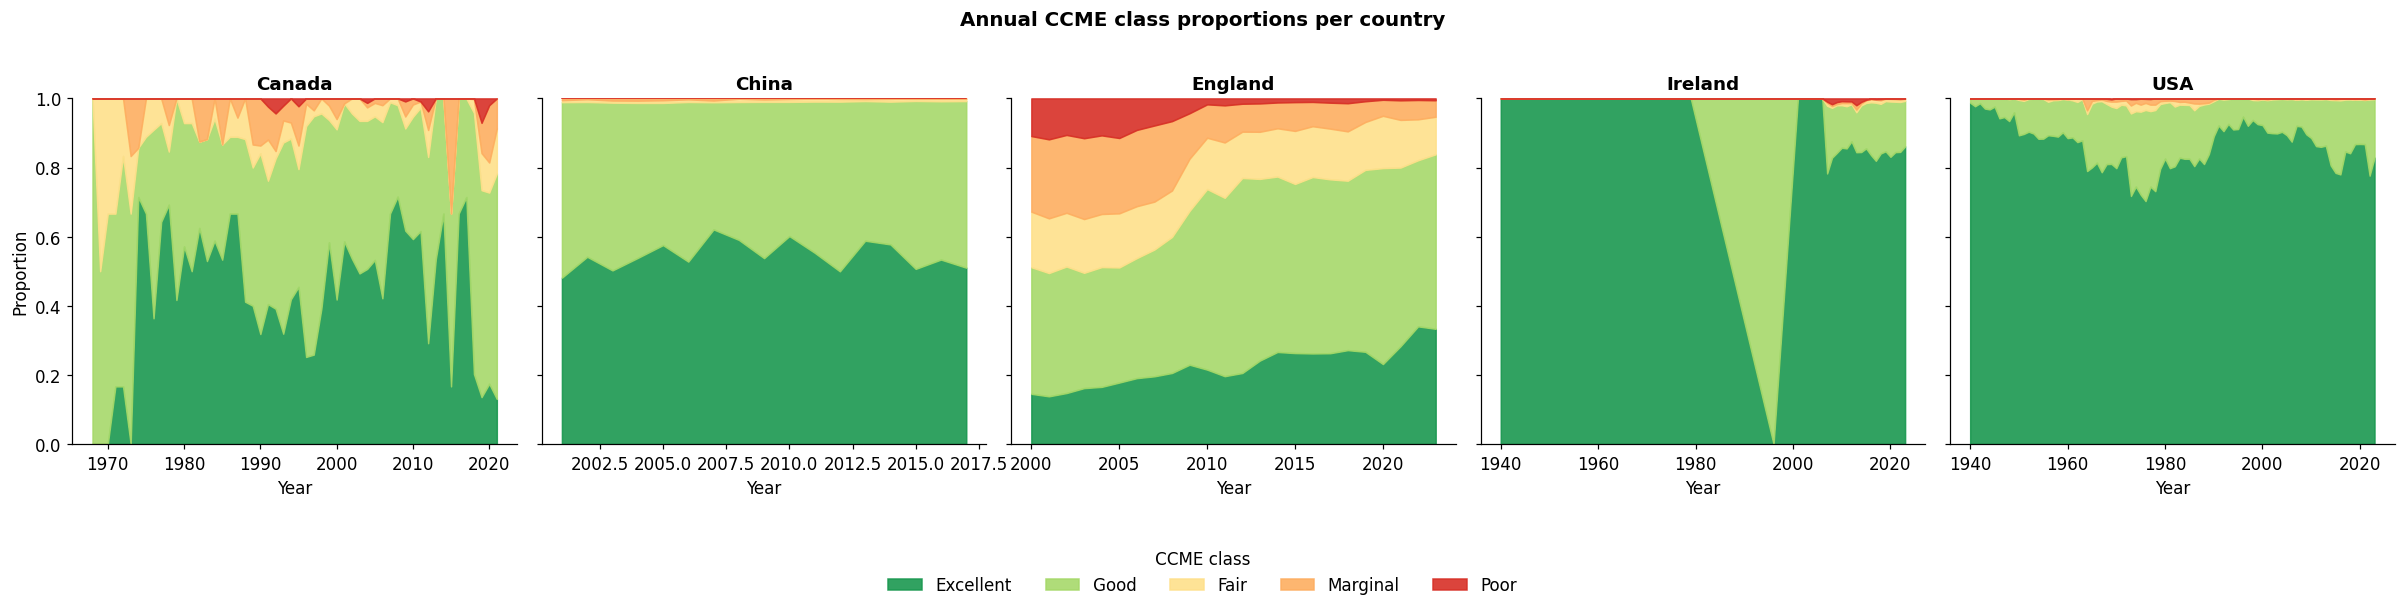

In [33]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5), sharey=True)
fig.suptitle("Annual CCME class proportions per country",
             fontsize=13, fontweight="bold", y=1.02)

for ax, country in zip(axes, COUNTRY_ORDER):
    df = dfs[country].copy()
    df["Year"] = df["Date"].dt.year
    
    yearly = (
        df.groupby(["Year", "CCME_WQI"]).size()
          .unstack(fill_value=0)
          .reindex(columns=CCME_CLASS_ORDER, fill_value=0)
    )
    yearly_prop = yearly.div(yearly.sum(axis=1), axis=0)

    bottom = np.zeros(len(yearly_prop))
    for cls in CCME_CLASS_ORDER:
        if cls not in yearly_prop.columns:
            continue
        ax.fill_between(yearly_prop.index, bottom, bottom + yearly_prop[cls],
                        color=CCME_CLASS_COLORS[cls], alpha=0.9, label=cls)
        bottom += yearly_prop[cls].values

    ax.set_title(country, fontweight="bold")
    ax.set_xlabel("Year")
    ax.set_ylim(0, 1)
    ax.grid(False)

axes[0].set_ylabel("Proportion")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5,
           bbox_to_anchor=(0.5, -0.04), frameon=False, title="CCME class")
plt.tight_layout()
save_figure("04_class_proportions_over_time")
plt.show()

# Section 5 — Temporal coverage analysis
*******************************************
**Goal:** determine defensible train / validation / test boundaries for
each country-client. The split must be:

1. **Chronological** — no random splitting; future data must never appear
   in training (Hyndman & Athanasopoulos, *Forecasting: P&P*, 3rd ed., §5.10).
2. **Common across clients** — the same calendar boundaries apply to all
   clients so that test-set evaluation is comparable.
3. **Data-supported** — each split must contain enough records in every
   client to produce usable monthly sequences.

We first examine raw annual observation counts (Section 5.1), then assess
real-data (non-imputed) coverage per year (Section 5.2), then evaluate
candidate boundary years (Section 5.3).

## 5.1 Raw observation count per year per country

✓ saved figure: 05_annual_obs_per_country.png/pdf


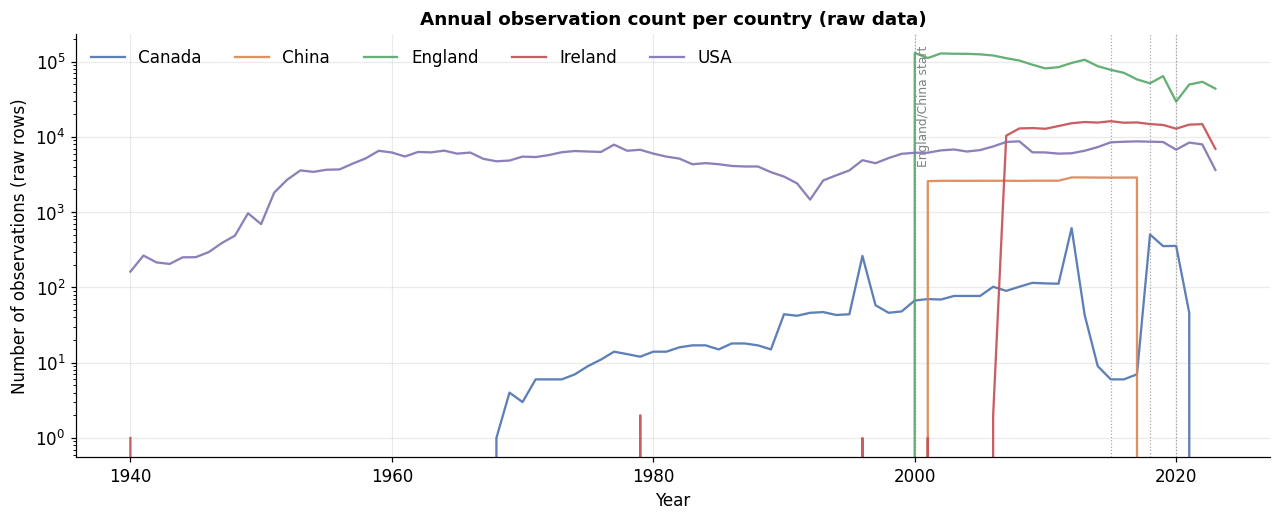

Last year with data per country:
  Canada    1968 → 2021
  China     2001 → 2017
  England   2000 → 2023
  Ireland   1940 → 2023
  USA       1940 → 2023


In [34]:
year_counts = {}
for country in COUNTRY_ORDER:
    df = dfs[country].copy()
    df["Year"] = df["Date"].dt.year
    year_counts[country] = df.groupby("Year").size()

all_years = range(
    min(yc.index.min() for yc in year_counts.values()),
    max(yc.index.max() for yc in year_counts.values()) + 1
)

fig, ax = plt.subplots(figsize=(14, 5))
for country in COUNTRY_ORDER:
    yc = year_counts[country].reindex(all_years, fill_value=0)
    ax.plot(yc.index, yc.values,
            color=COUNTRY_COLORS[country], label=country,
            linewidth=1.5, alpha=0.9)

ax.set_xlabel("Year")
ax.set_ylabel("Number of observations (raw rows)")
ax.set_title("Annual observation count per country (raw data)",
             fontweight="bold")
ax.set_yscale("log")
ax.legend(frameon=False, ncol=5, loc="upper left")

# Mark key temporal boundaries for reference
for yr, label in [(2000, "England/China start"), (2015, ""), (2018, ""), (2020, "")]:
    ax.axvline(yr, color="gray", linewidth=0.8, linestyle=":", alpha=0.7)
    if label:
        ax.text(yr + 0.2, ax.get_ylim()[1] * 0.7, label,
                fontsize=8, color="gray", rotation=90, va="top")

save_figure("05_annual_obs_per_country")
plt.show()

# Print the last year with data per country
print("Last year with data per country:")
for country in COUNTRY_ORDER:
    last = year_counts[country].index.max()
    first = year_counts[country].index.min()
    print(f"  {country:8s}  {first} → {last}")

### Year × country density heatmap

✓ saved figure: 05_temporal_heatmap.png/pdf


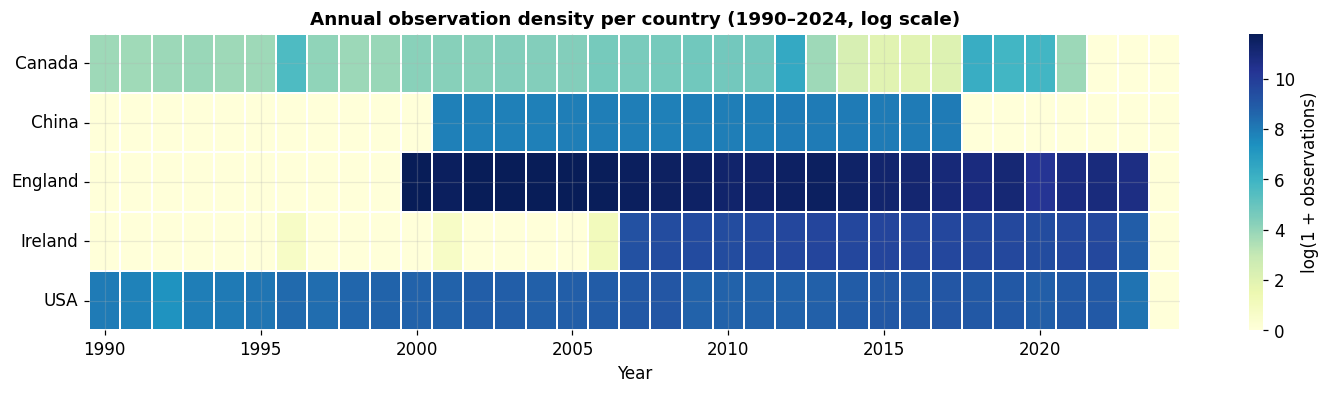

In [35]:
# Build year × country matrix for heatmap
year_range = list(range(1990, 2025))   # focus on most data-rich period
heatmap_data = pd.DataFrame(index=COUNTRY_ORDER, columns=year_range, dtype=float)

for country in COUNTRY_ORDER:
    for yr in year_range:
        heatmap_data.loc[country, yr] = year_counts[country].get(yr, 0)

# Log-transform (log1p to handle zeros gracefully)
heatmap_log = np.log1p(heatmap_data.astype(float))

fig, ax = plt.subplots(figsize=(16, 3.5))
sns.heatmap(heatmap_log, ax=ax, cmap="YlGnBu",
            cbar_kws={"label": "log(1 + observations)"},
            linewidths=0.3, linecolor="white",
            xticklabels=5)   # show every 5th year label
ax.set_title("Annual observation density per country (1990–2024, log scale)",
             fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("")
save_figure("05_temporal_heatmap")
plt.show()

## 5.2 Real-data temporal coverage (deferred to Stage 2)

The real-data temporal coverage analysis — quantifying, per year, what
fraction of records are non-imputed — is most informative for the
de-imputed Stage 2 pipeline. Stage 1 uses the dataset as published;
we defer this analysis to the Stage 2 EDA refresh.

## 5.3 Candidate train / validation / test boundary evaluation

In [36]:
# Candidate boundary evaluation
# We test train / val / test splits defined by two cut years:
#   train: Date <  val_start
#   val:   val_start <= Date < test_start
#   test:  Date >= test_start

candidates = [
    (2013, 2015),   # test = 2015-2017 → keeps China; but test is old
    (2014, 2016),
    (2015, 2017),   # test starts 2017 → China gets only Dec 2017
    (2016, 2018),   # test starts 2018 → China has NO test data
    (2017, 2019),
    (2018, 2020),   # test = 2020-2023 → modern, but China excluded
]

eval_rows = []
for val_start, test_start in candidates:
    for country in COUNTRY_ORDER:
        df = dfs[country]
        n_train = int((df["Date"].dt.year < val_start).sum())
        n_val   = int(((df["Date"].dt.year >= val_start) &
                       (df["Date"].dt.year < test_start)).sum())
        n_test  = int((df["Date"].dt.year >= test_start).sum())
        eval_rows.append({
            "Val_start":  val_start,
            "Test_start": test_start,
            "Country":    country,
            "N_train":    n_train,
            "N_val":      n_val,
            "N_test":     n_test,
            "Train_%":    round(100 * n_train / len(df), 1) if len(df) else 0,
            "Has_test":   n_test > 0,
        })

split_eval = pd.DataFrame(eval_rows)
save_table(split_eval, "05_split_boundary_eval")

# Summary pivot: countries with zero test data per candidate split
print("Countries with ZERO test records per candidate split:\n")
for val_start, test_start in candidates:
    sub = split_eval[
        (split_eval["Val_start"] == val_start) &
        (split_eval["Test_start"] == test_start)
    ]
    missing = sub[sub["Has_test"] == False]["Country"].tolist()
    china_test = int(sub[sub["Country"] == "China"]["N_test"].values[0])
    print(f"  val≥{val_start}, test≥{test_start}  →  "
          f"no test data: {missing if missing else 'none'}  "
          f"(China test records: {china_test:,})")

print()
# Per-country record counts for the two most realistic candidates
for val_start, test_start in [(2015, 2017), (2018, 2020)]:
    print(f"\n── Split: train < {val_start} | val {val_start}–{test_start-1} | "
          f"test ≥ {test_start} ──")
    sub = split_eval[
        (split_eval["Val_start"] == val_start) &
        (split_eval["Test_start"] == test_start)
    ][["Country", "N_train", "N_val", "N_test", "Train_%"]]
    print(sub.to_string(index=False))

✓ saved table : 05_split_boundary_eval.csv  (30×8)
Countries with ZERO test records per candidate split:

  val≥2013, test≥2015  →  no test data: none  (China test records: 8,642)
  val≥2014, test≥2016  →  no test data: none  (China test records: 5,765)
  val≥2015, test≥2017  →  no test data: none  (China test records: 2,885)
  val≥2016, test≥2018  →  no test data: ['China']  (China test records: 0)
  val≥2017, test≥2019  →  no test data: ['China']  (China test records: 0)
  val≥2018, test≥2020  →  no test data: ['China']  (China test records: 0)


── Split: train < 2015 | val 2015–2016 | test ≥ 2017 ──
Country  N_train  N_val  N_test  Train_%
 Canada     2670     12    1267     67.6
  China    37355   5757    2885     81.2
England  1630035 148702  350461     76.6
Ireland   109590  31590   93839     46.6
    USA   344078  17093   52643     83.1

── Split: train < 2018 | val 2018–2019 | test ≥ 2020 ──
Country  N_train  N_val  N_test  Train_%
 Canada     2689    858     402     68.1
  Ch

### Record volume comparison across candidate splits

✓ saved figure: 05_split_volume_comparison.png/pdf


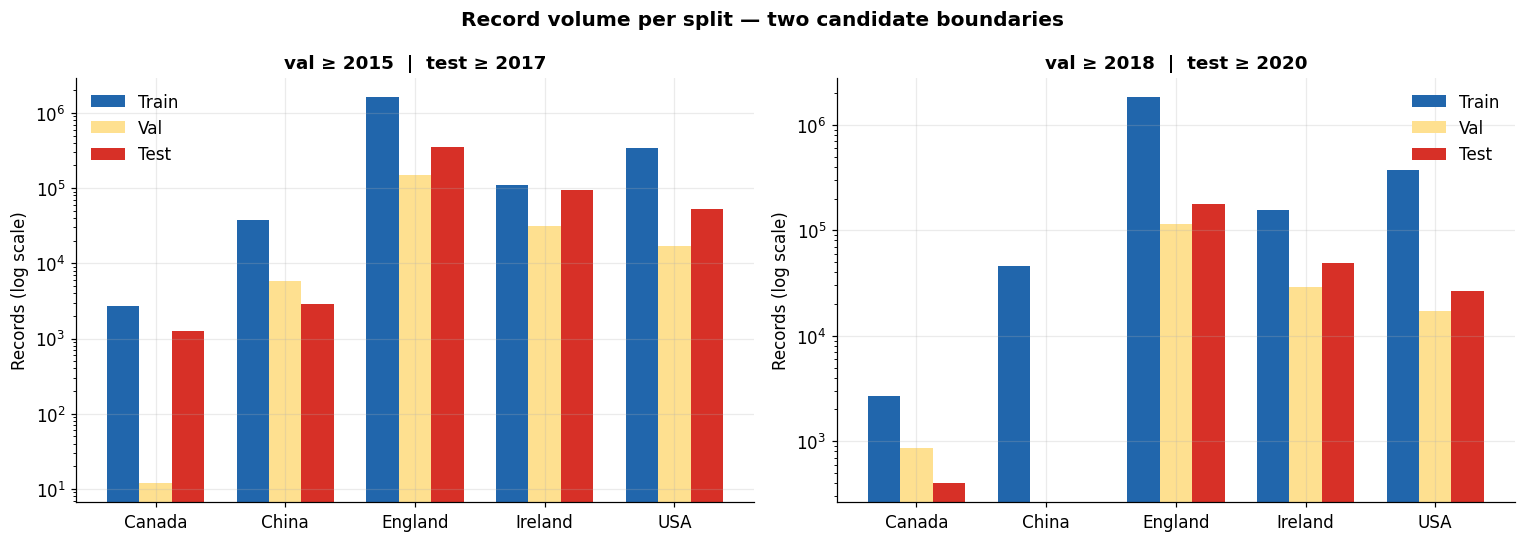

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Record volume per split — two candidate boundaries",
             fontweight="bold")

for ax, (val_start, test_start) in zip(axes, [(2015, 2017), (2018, 2020)]):
    sub = split_eval[
        (split_eval["Val_start"] == val_start) &
        (split_eval["Test_start"] == test_start)
    ].set_index("Country")

    x = np.arange(len(COUNTRY_ORDER))
    w = 0.25
    ax.bar(x - w, sub.loc[COUNTRY_ORDER, "N_train"], width=w,
           label="Train", color="#2166ac")
    ax.bar(x,     sub.loc[COUNTRY_ORDER, "N_val"],   width=w,
           label="Val",   color="#fee090")
    ax.bar(x + w, sub.loc[COUNTRY_ORDER, "N_test"],  width=w,
           label="Test",  color="#d73027")
    ax.set_xticks(x)
    ax.set_xticklabels(COUNTRY_ORDER)
    ax.set_yscale("log")
    ax.set_ylabel("Records (log scale)")
    ax.set_title(f"val ≥ {val_start}  |  test ≥ {test_start}",
                 fontweight="bold")
    ax.legend(frameon=False)

plt.tight_layout()
save_figure("05_split_volume_comparison")
plt.show()

# Section 6 — Sequence-modeling feasibility
******************************************
We simulate the Stage 1 preprocessing pipeline on a copy of each
country's data (no mutation of `dfs`), then count usable monthly
sequences in each split under the proposed boundaries.

A sequence is built by sliding a window of `L = 12` months with a
target at horizon `h = 1`. The sequence is valid if all 12 window
months have non-NaN features and the target month carries a valid
CCME score.

The output of this section is the empirical confirmation (or revision)
of the candidate split and the final client set.

### Helper functions

In [38]:
def simulate_stage1_preprocessing(df_country):
    """
    Apply the Stage 1 preprocessing operations on a COPY of a country's
    raw dataframe. Returns a monthly-resampled DataFrame: one row per
    (site_id, end-of-month).
    """
    df = df_country.copy()

    # 1. Drop exact duplicates
    df = df.drop_duplicates()

    # 2. Drop physically invalid rows
    for col, (lo, hi) in VALIDITY_RULES.items():
        if lo is not None:
            df = df[~(df[col] < lo)]
        if hi is not None:
            df = df[~(df[col] > hi)]

    # 3. Aggregate same-(site_id, Date) rows by per-feature median
    agg_cols = FEATURE_COLS + ["CCME_Values"]
    df_agg = (df.groupby(["site_id", "Date"], as_index=False)[agg_cols]
                .median())

    # 4. Monthly-resample per site, per-feature median across the month
    df_agg = df_agg.set_index("Date")
    monthly = (df_agg.groupby("site_id")[agg_cols]
                     .resample("ME")
                     .median()
                     .reset_index())
    return monthly


def count_valid_sequences(monthly_df, window=12, horizon=1):
    """
    Count valid sequences in a country's monthly-resampled data.
    Returns a DataFrame: one row per valid sequence with
    columns (site_id, target_date, target_year).
    """
    L, h = window, horizon
    records = []

    for site_id, sdf in monthly_df.groupby("site_id"):
        sdf = sdf.sort_values("Date").reset_index(drop=True)
        n = len(sdf)
        if n < L + h:
            continue

        valid_features = (~sdf[FEATURE_COLS].isna().any(axis=1)).values
        valid_target   = (~sdf["CCME_Values"].isna()).values
        dates          = sdf["Date"].values

        for i in range(n - L - h + 1):
            target_idx = i + L + h - 1
            if valid_features[i:i+L].all() and valid_target[target_idx]:
                records.append({
                    "site_id":     site_id,
                    "target_date": dates[target_idx],
                    "target_year": pd.Timestamp(dates[target_idx]).year,
                })

    return pd.DataFrame(records)

## 6.1 Simulation per country

In [39]:
monthly_data    = {}
sequence_data   = {}

print("Simulating Stage 1 preprocessing pipeline (this takes a few minutes):\n")
print(f"{'Country':10s} {'Raw rows':>12s} {'Monthly rows':>14s} {'Valid seq':>12s} {'Time':>8s}")
print("-" * 60)

for country in COUNTRY_ORDER:
    t0 = time.time()
    monthly = simulate_stage1_preprocessing(dfs[country])
    seq     = count_valid_sequences(monthly, window=12, horizon=1)
    monthly_data[country]  = monthly
    sequence_data[country] = seq
    elapsed = time.time() - t0
    print(f"{country:10s} {len(dfs[country]):>12,} {len(monthly):>14,} "
          f"{len(seq):>12,} {elapsed:>7.1f}s")

Simulating Stage 1 preprocessing pipeline (this takes a few minutes):

Country        Raw rows   Monthly rows    Valid seq     Time
------------------------------------------------------------
Canada            3,949         57,327            0     3.9s
China            45,997            204          192     0.1s
England       2,129,198      5,275,901       96,962   179.1s
Ireland         235,019        584,745       37,961    23.6s
USA             413,814        108,751       33,971     3.6s


## 6.2 Sequence counts under the proposed split

In [40]:
VAL_START  = 2018
TEST_START = 2020

split_rows = []
for country in COUNTRY_ORDER:
    seq = sequence_data[country]
    if len(seq) == 0:
        n_train = n_val = n_test = 0
    else:
        n_train = int((seq["target_year"] <  VAL_START).sum())
        n_val   = int(((seq["target_year"] >= VAL_START) &
                       (seq["target_year"] <  TEST_START)).sum())
        n_test  = int((seq["target_year"] >= TEST_START).sum())
    total = n_train + n_val + n_test
    split_rows.append({
        "Country":   country,
        "Train_seq": n_train,
        "Val_seq":   n_val,
        "Test_seq":  n_test,
        "Total_seq": total,
        "Has_test":  n_test > 0,
    })

split_counts = pd.DataFrame(split_rows)
save_table(split_counts, "06_sequence_counts_by_split")

print(f"\nProposed split: train < {VAL_START} | val {VAL_START}-{TEST_START-1} | "
      f"test ≥ {TEST_START}, window=12, horizon=1\n")
print(split_counts.to_string(index=False))

✓ saved table : 06_sequence_counts_by_split.csv  (5×6)

Proposed split: train < 2018 | val 2018-2019 | test ≥ 2020, window=12, horizon=1

Country  Train_seq  Val_seq  Test_seq  Total_seq  Has_test
 Canada          0        0         0          0     False
  China        192        0         0        192     False
England      76530     8490     11942      96962      True
Ireland      27778     4296      5887      37961      True
    USA      30222     1770      1979      33971      True


### Sequence-count bar chart

✓ saved figure: 06_sequence_counts_per_split.png/pdf


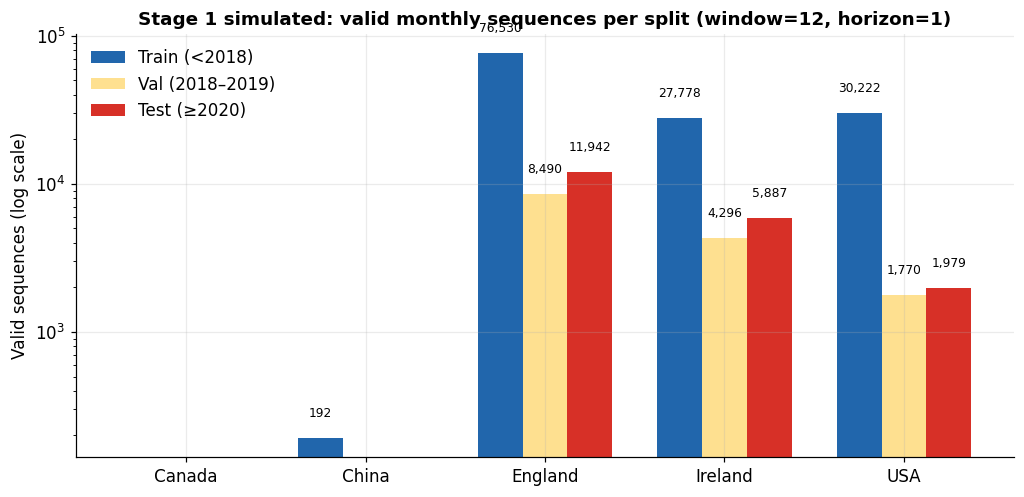

In [41]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(COUNTRY_ORDER))
w = 0.25

ax.bar(x - w, split_counts["Train_seq"], width=w,
       label=f"Train (<{VAL_START})",  color="#2166ac")
ax.bar(x,     split_counts["Val_seq"],   width=w,
       label=f"Val ({VAL_START}–{TEST_START-1})", color="#fee090")
ax.bar(x + w, split_counts["Test_seq"],  width=w,
       label=f"Test (≥{TEST_START})",  color="#d73027")

ax.set_xticks(x)
ax.set_xticklabels(COUNTRY_ORDER)
ax.set_ylabel("Valid sequences (log scale)")
ax.set_yscale("log")
ax.set_title("Stage 1 simulated: valid monthly sequences per split "
             "(window=12, horizon=1)",
             fontweight="bold")
ax.legend(frameon=False)

# Annotate non-zero bars with the count
for i, row in split_counts.iterrows():
    for offset, key in [(-w, "Train_seq"), (0, "Val_seq"), (w, "Test_seq")]:
        v = row[key]
        if v > 0:
            ax.text(i + offset, v * 1.4, f"{v:,}",
                    ha="center", fontsize=8)

save_figure("06_sequence_counts_per_split")
plt.show()

## 6.3 Sensitivity to window and horizon

In [42]:
# Test window/horizon trade-offs
configs = [(6, 1), (12, 1), (24, 1), (12, 3), (12, 6)]

sens_rows = []
for L, h in configs:
    for country in COUNTRY_ORDER:
        seq = count_valid_sequences(monthly_data[country], window=L, horizon=h)
        if len(seq) == 0:
            n_train = n_val = n_test = 0
        else:
            n_train = int((seq["target_year"] <  VAL_START).sum())
            n_val   = int(((seq["target_year"] >= VAL_START) &
                           (seq["target_year"] <  TEST_START)).sum())
            n_test  = int((seq["target_year"] >= TEST_START).sum())
        sens_rows.append({
            "Window":  L,
            "Horizon": h,
            "Country": country,
            "Train":   n_train,
            "Val":     n_val,
            "Test":    n_test,
        })

sensitivity = pd.DataFrame(sens_rows)
save_table(sensitivity, "06_window_horizon_sensitivity")

# Pivot for readability: each (L, h) config → train counts per country
print("\nTrain sequences by (window, horizon) and country:")
print(sensitivity.pivot_table(index=["Window", "Horizon"],
                              columns="Country",
                              values="Train",
                              aggfunc="sum"))
print("\nTest sequences by (window, horizon) and country:")
print(sensitivity.pivot_table(index=["Window", "Horizon"],
                              columns="Country",
                              values="Test",
                              aggfunc="sum"))

✓ saved table : 06_window_horizon_sensitivity.csv  (25×6)

Train sequences by (window, horizon) and country:
Country         Canada  China  England  Ireland    USA
Window Horizon                                        
6      1             0    198   207344    37609  34371
12     1             0    192    76530    27778  30222
       3             0    190    74428    27101  29917
       6             0    187    71141    26138  29506
24     1             0    180    24452    19099  25386

Test sequences by (window, horizon) and country:
Country         Canada  China  England  Ireland   USA
Window Horizon                                       
6      1             0      0    38338     8210  2513
12     1             0      0    11942     5887  1979
       3             0      0    10629     6028  1974
       6             0      0     9167     6156  2028
24     1             0      0     1892     3865  1057


### Sensitivity heatmap

✓ saved figure: 06_sensitivity_heatmap.png/pdf


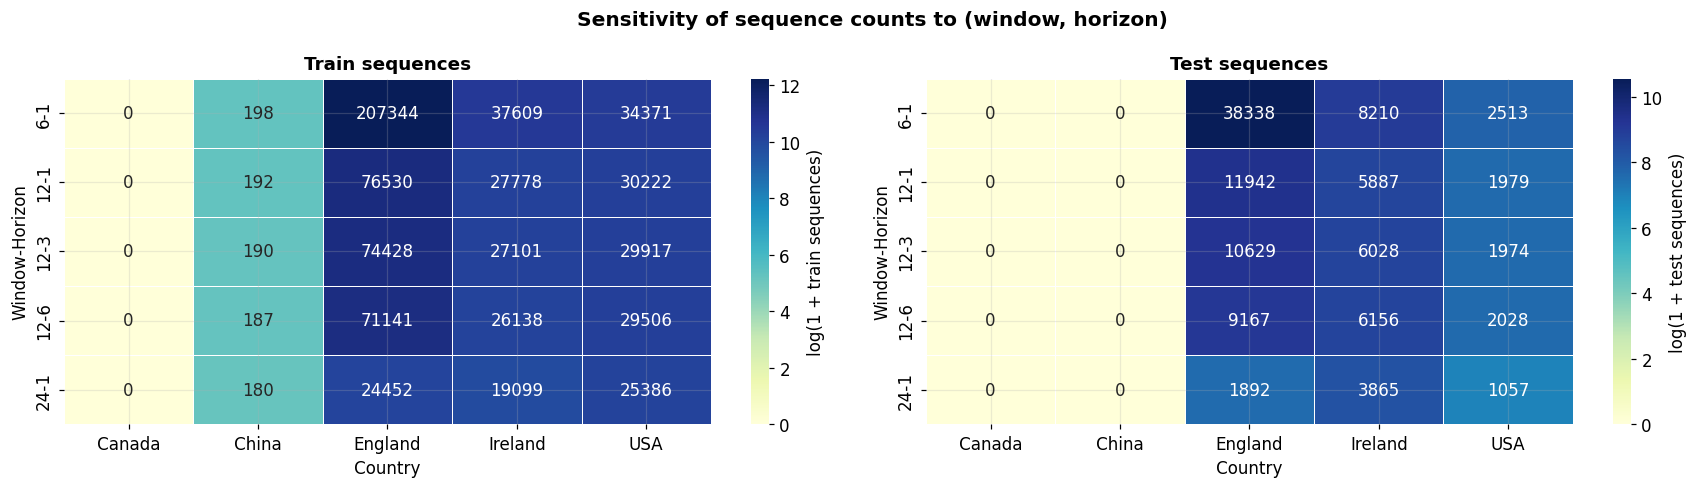

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
fig.suptitle("Sensitivity of sequence counts to (window, horizon)",
             fontweight="bold")

for ax, metric in zip(axes, ["Train", "Test"]):
    p = sensitivity.pivot_table(
        index=["Window", "Horizon"],
        columns="Country",
        values=metric,
        aggfunc="sum"
    )[COUNTRY_ORDER]
    sns.heatmap(np.log1p(p), annot=p.astype(int).values, fmt="d",
                cmap="YlGnBu", ax=ax,
                cbar_kws={"label": f"log(1 + {metric.lower()} sequences)"},
                linewidths=0.4, linecolor="white")
    ax.set_title(f"{metric} sequences", fontweight="bold")

plt.tight_layout()
save_figure("06_sensitivity_heatmap")
plt.show()

# Section 7 — Cross-country heterogeneity (formal statistical testing)
********************************
We quantify how statistically distinct the three confirmed federation
clients (England, Ireland, USA) are on the feature space and the label
space. This provides the empirical justification for using federated
rather than centralized learning.

**Methods.**
- *Kolmogorov–Smirnov (KS) distance* for each continuous feature, pairwise
  between clients. Scale-invariant, bounded in [0, 1]. Standard non-IID
  measure in cross-silo FL (Hsu, Qi & Brown, 2019).
- *Jensen–Shannon divergence (JSD)* for the discrete CCME class
  distribution, pairwise between clients. Symmetric, bounded in [0, log 2].
  Canonical measure for categorical distribution divergence
  (Lin, 1991, *IEEE TIT*).

**Note on Stage 1**: heterogeneity is measured on the dataset as
published (imputed values included). The observed differences mix real
cross-country variation with imputation-pattern variation. This will be
re-measured on de-imputed data in Stage 2.

## 7.1 Feature distribution heterogeneity (Kolmogorov–Smirnov)

In [44]:
# Restrict to the three active clients selected after sequence-feasibility analysis
ACTIVE_CLIENTS = ["England", "Ireland", "USA"]

# Pairwise KS distance per feature
ks_rows = []
for col in FEATURE_COLS:
    for c1, c2 in combinations(ACTIVE_CLIENTS, 2):
        x1 = dfs[c1][col].dropna().values
        x2 = dfs[c2][col].dropna().values
        stat, _ = ks_2samp(x1, x2)
        ks_rows.append({
            "Parameter": col,
            "Pair":      f"{c1}↔{c2}",
            "KS":        round(stat, 4),
            "N1":        len(x1),
            "N2":        len(x2),
        })

ks_df    = pd.DataFrame(ks_rows)
ks_pivot = ks_df.pivot(index="Parameter", columns="Pair", values="KS")

save_table(ks_df,    "07_ks_distances_long")
save_table(ks_pivot.reset_index(), "07_ks_distances_pivot")

print("Kolmogorov–Smirnov distances per feature × pair "
      "(0 = identical, 1 = disjoint):\n")
print(ks_pivot.round(3))

✓ saved table : 07_ks_distances_long.csv  (24×5)
✓ saved table : 07_ks_distances_pivot.csv  (8×4)
Kolmogorov–Smirnov distances per feature × pair (0 = identical, 1 = disjoint):

Pair       England↔Ireland  England↔USA  Ireland↔USA
Parameter                                           
BOD                  0.630        0.766        0.810
DO                   0.367        0.488        0.369
NH3                  0.440        0.939        0.811
Nitrate              0.675        0.708        0.664
Nitrogen             0.571        0.862        0.796
PO4                  0.634        0.688        0.696
Temp                 0.131        0.258        0.191
pH                   0.116        0.341        0.225


### KS distance heatmap

✓ saved figure: 07_ks_heatmap.png/pdf


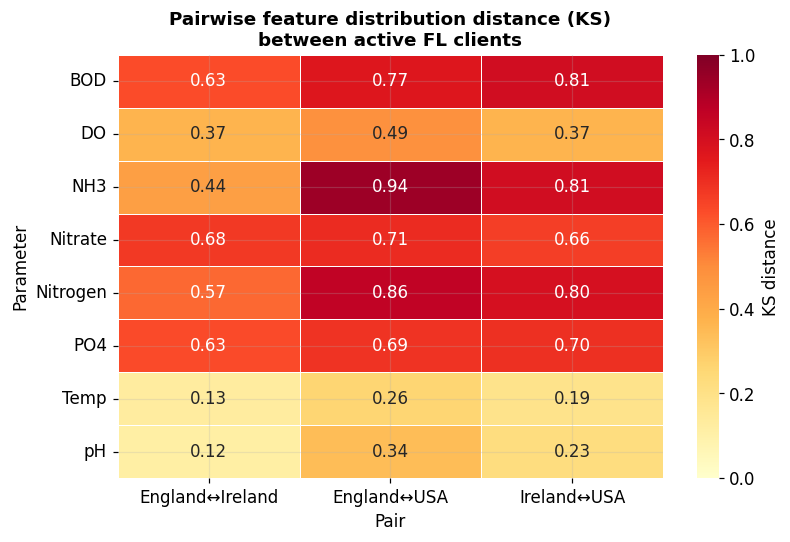

In [45]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(ks_pivot, annot=True, fmt=".2f", cmap="YlOrRd",
            vmin=0, vmax=1, cbar_kws={"label": "KS distance"},
            ax=ax, linewidths=0.5, linecolor="white")
ax.set_title("Pairwise feature distribution distance (KS)\n"
             "between active FL clients",
             fontweight="bold")
save_figure("07_ks_heatmap")
plt.show()

## 7.2 Label distribution heterogeneity (Jensen–Shannon)

We compare the empirical CCME class distributions pairwise between
clients. JSD = 0 implies identical class proportions; JSD = log 2 ≈ 0.693
implies maximal categorical divergence.

In [46]:
# Build per-client class probability vectors over the canonical class order
class_probs = {}
for c in ACTIVE_CLIENTS:
    counts = dfs[c]["CCME_WQI"].value_counts()
    counts = counts.reindex(CCME_CLASS_ORDER, fill_value=0)
    class_probs[c] = (counts / counts.sum()).values

jsd_rows = []
for c1, c2 in combinations(ACTIVE_CLIENTS, 2):
    # scipy's jensenshannon returns the metric (sqrt of divergence);
    # square it to get the divergence itself
    jsd = jensenshannon(class_probs[c1], class_probs[c2]) ** 2
    jsd_rows.append({
        "Pair":     f"{c1}↔{c2}",
        "JSD":      round(jsd, 4),
        "JSD_norm": round(jsd / np.log(2), 4),   # normalize to [0, 1]
    })

jsd_df = pd.DataFrame(jsd_rows)
save_table(jsd_df, "07_label_jsd")

print("Jensen–Shannon divergence on CCME class distribution:\n")
print(jsd_df.to_string(index=False))
print(f"\nMaximum possible JSD = log(2) = {np.log(2):.4f}")

✓ saved table : 07_label_jsd.csv  (3×3)
Jensen–Shannon divergence on CCME class distribution:

           Pair    JSD  JSD_norm
England↔Ireland 0.2378    0.3430
    England↔USA 0.2462    0.3551
    Ireland↔USA 0.0017    0.0025

Maximum possible JSD = log(2) = 0.6931


### Class distribution comparison figure

✓ saved figure: 07_class_dist_comparison_active_clients.png/pdf


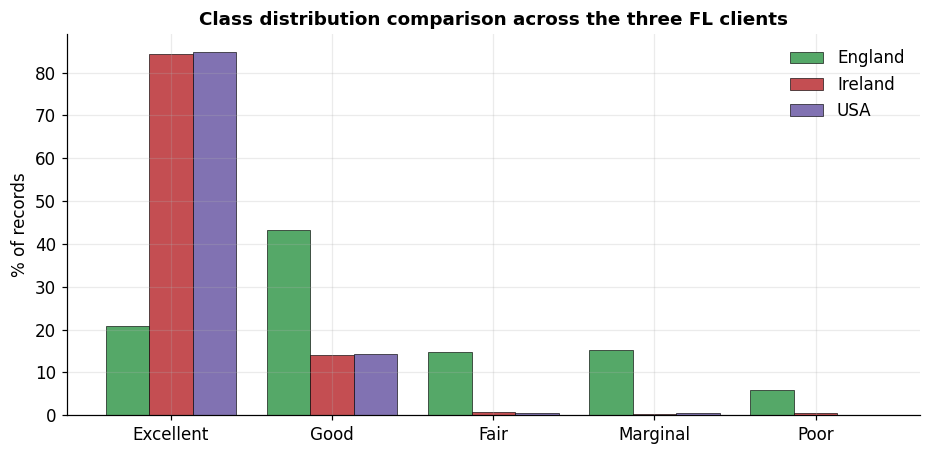

In [47]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(CCME_CLASS_ORDER))
w = 0.27

for i, country in enumerate(ACTIVE_CLIENTS):
    offset = (i - 1) * w
    bars = ax.bar(x + offset,
                  class_probs[country] * 100,
                  width=w,
                  color=COUNTRY_COLORS[country],
                  edgecolor="black", linewidth=0.4,
                  label=country)

ax.set_xticks(x)
ax.set_xticklabels(CCME_CLASS_ORDER)
ax.set_ylabel("% of records")
ax.set_title("Class distribution comparison across the three FL clients",
             fontweight="bold")
ax.legend(frameon=False)
save_figure("07_class_dist_comparison_active_clients")
plt.show()

## 7.3 Heterogeneity summary

A single table combining feature-level KS distances (averaged across all
8 features) with label-level JSD per client pair. This is what feeds
Chapter 3's "why federated learning" paragraph.

In [48]:
#synthesis table
summary_rows = []
for c1, c2 in combinations(ACTIVE_CLIENTS, 2):
    pair = f"{c1}↔{c2}"
    # Mean KS across features
    mean_ks = ks_df[ks_df["Pair"] == pair]["KS"].mean()
    max_ks  = ks_df[ks_df["Pair"] == pair]["KS"].max()
    max_ks_feat = ks_df[ks_df["Pair"] == pair].loc[
        ks_df[ks_df["Pair"] == pair]["KS"].idxmax(), "Parameter"]
    # JSD for label distribution
    jsd = jsd_df[jsd_df["Pair"] == pair]["JSD"].values[0]
    summary_rows.append({
        "Pair":                pair,
        "Mean_feature_KS":     round(mean_ks, 3),
        "Max_feature_KS":      round(max_ks, 3),
        "Most_divergent_feature": max_ks_feat,
        "Label_JSD":           round(jsd, 3),
        "Label_JSD_normalized": round(jsd / np.log(2), 3),
    })

heterogeneity_summary = pd.DataFrame(summary_rows)
save_table(heterogeneity_summary, "07_heterogeneity_summary")
print("Heterogeneity synthesis across active FL clients:\n")
print(heterogeneity_summary.to_string(index=False))

✓ saved table : 07_heterogeneity_summary.csv  (3×6)
Heterogeneity synthesis across active FL clients:

           Pair  Mean_feature_KS  Max_feature_KS Most_divergent_feature  Label_JSD  Label_JSD_normalized
England↔Ireland            0.445           0.675                Nitrate      0.238                 0.343
    England↔USA            0.631           0.939                    NH3      0.246                 0.355
    Ireland↔USA            0.570           0.811                    NH3      0.002                 0.002


# Section 8 — Federation feasibility synthesis

A single consolidated table summarizing every per-client EDA finding:
data volume, temporal coverage, imputation severity, class imbalance,
sequence-modeling viability, and the inclusion decision with its
empirical basis.

This table is the chapter-ready summary deliverable for the methodology
chapter (Chapter 3, "Per-client dataset characterization").

In [49]:
synthesis_rows = []
for country in COUNTRY_ORDER:
    df = dfs[country]
    
    # From Section 1 / inventory
    n_rows   = len(df)
    date_min = df["Date"].min().strftime("%Y-%m-%d")
    date_max = df["Date"].max().strftime("%Y-%m-%d")
    n_sites  = df["site_id"].nunique()
    median_obs_site = int(df.groupby("site_id").size().median())
    
    # From Section 2 imputation finding
    country_imputed = mode_df[mode_df["Country"] == country]
    n_affected = int((country_imputed["Modal_%"] > IMPUTATION_THRESHOLD_PCT).sum())
    max_imp_pct = country_imputed["Modal_%"].max()
    most_imp_param = country_imputed.loc[
        country_imputed["Modal_%"].idxmax(), "Parameter"]
    
    # From Section 4 class distribution
    counts = df["CCME_WQI"].value_counts(normalize=True) * 100
    dom_class = counts.idxmax()
    dom_pct   = counts.max()
    
    # From Section 6 sequence counts
    row = split_counts[split_counts["Country"] == country].iloc[0]
    n_train_seq = int(row["Train_seq"])
    n_val_seq   = int(row["Val_seq"])
    n_test_seq  = int(row["Test_seq"])
    
    # Decision
    if n_train_seq == 0:
        decision = "Excluded"
        reason   = "0 valid training sequences (per-site coverage too sparse)"
    elif n_test_seq == 0:
        decision = "Excluded"
        reason   = "0 test sequences (data ends before test window)"
    else:
        decision = "Included"
        reason   = "viable sequence counts in all splits"
    
    synthesis_rows.append({
        "Country":               country,
        "N_raw_rows":            n_rows,
        "Date_range":            f"{date_min} → {date_max}",
        "N_sites":               n_sites,
        "Median_obs/site":       median_obs_site,
        "Imputed_params (>30%)": n_affected,
        "Max_imputation_%":      f"{max_imp_pct:.1f} ({most_imp_param})",
        "Dominant_class":        f"{dom_class} ({dom_pct:.0f}%)",
        "Train_seq":             n_train_seq,
        "Val_seq":               n_val_seq,
        "Test_seq":              n_test_seq,
        "Federation_decision":   decision,
        "Reason":                reason,
    })

synthesis = pd.DataFrame(synthesis_rows)
save_table(synthesis, "08_federation_feasibility_synthesis")

# Pretty display
print("Federation feasibility synthesis:\n")
print(synthesis.to_string(index=False))

✓ saved table : 08_federation_feasibility_synthesis.csv  (5×13)
Federation feasibility synthesis:

Country  N_raw_rows              Date_range  N_sites  Median_obs/site  Imputed_params (>30%) Max_imputation_%  Dominant_class  Train_seq  Val_seq  Test_seq Federation_decision                                                    Reason
 Canada        3949 1968-01-12 → 2021-02-15     2354                1                      2  70.2 (Nitrogen)      Good (52%)          0        0         0            Excluded 0 valid training sequences (per-site coverage too sparse)
  China       45997 2001-01-03 → 2017-12-16        1            45997                      1        36.6 (DO) Excellent (55%)        192        0         0            Excluded           0 test sequences (data ends before test window)
England     2129198 2000-01-01 → 2023-10-23    56317                9                      3        41.8 (DO)      Good (43%)      76530     8490     11942            Included                      vi

✓ saved figure: 08_federation_decision.png/pdf


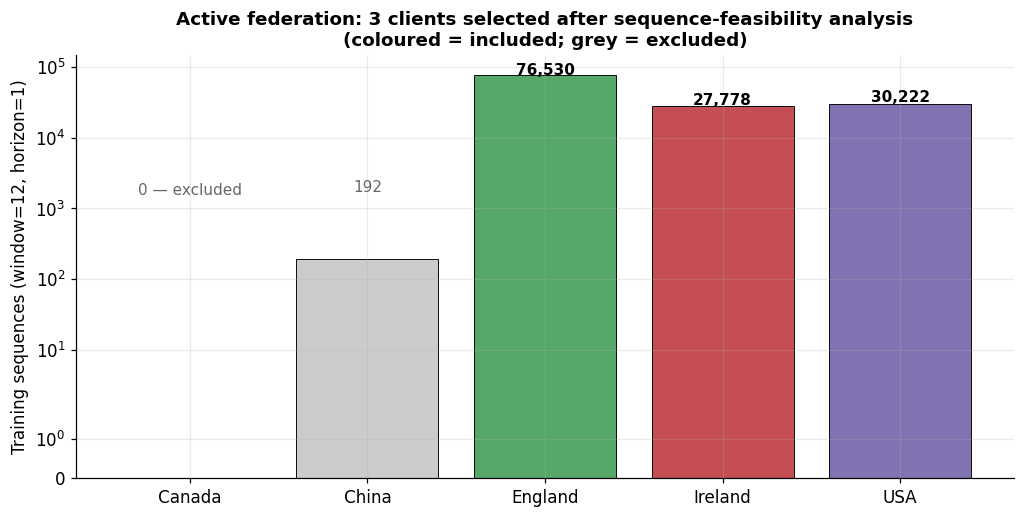

In [50]:
# Compact visual: bar chart of train sequences with inclusion shaded
fig, ax = plt.subplots(figsize=(11, 5))
n_train = synthesis["Train_seq"].values
included = (synthesis["Federation_decision"] == "Included").values
colors = [COUNTRY_COLORS[c] if inc else "#cccccc"
          for c, inc in zip(synthesis["Country"], included)]

bars = ax.bar(synthesis["Country"], n_train,
              color=colors, edgecolor="black", linewidth=0.6)

for bar, n, inc in zip(bars, n_train, included):
    label = f"{n:,}" if n > 0 else "0 — excluded"
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + max(n_train) * 0.02,
            label, ha="center", fontsize=10,
            fontweight="bold" if inc else "normal",
            color="black" if inc else "#666666")

ax.set_yscale("symlog")
ax.set_ylabel("Training sequences (window=12, horizon=1)")
ax.set_title("Active federation: 3 clients selected after sequence-feasibility analysis\n"
             "(coloured = included; grey = excluded)",
             fontweight="bold")
save_figure("08_federation_decision")
plt.show()

In [51]:
# ──────────────────────────────────────────────────────────────────────
# Download bundle — zip all figures and tables for easy export
# ──────────────────────────────────────────────────────────────────────
import shutil

archive_path = shutil.make_archive(
    base_name="/kaggle/working/eda_outputs_archive",
    format="zip",
    root_dir=OUTPUT_DIR,
)

archive_size_mb = os.path.getsize(archive_path) / (1024 * 1024)
print(f"Created: {archive_path}")
print(f"Size:    {archive_size_mb:.2f} MB")

# Print a manifest so you can see what's inside
print("\nContents:")
for d, label in [(FIG_DIR, "Figures"), (TABLE_DIR, "Tables")]:
    files = sorted(os.listdir(d))
    print(f"  {label} ({len(files)} files)")

Created: /kaggle/working/eda_outputs_archive.zip
Size:    3.16 MB

Contents:
  Figures (38 files)
  Tables (31 files)


## EDA conclusion

The exploratory data analysis is complete. The following methodological decisions are supported by the EDA:

- **Federation**: 3 selected cross-silo clients — England, Ireland, USA.

- **Excluded clients**: Canada and China were excluded from the main Stage 1 federation based on the sequence-feasibility analysis. Canada was excluded because its per-site monthly coverage produces zero valid training sequences under any tested configuration. China was excluded because its data ends in December 2017, leaving no records within the selected test window.

- **Forecasting task**: sequence-to-class forecasting with a window of 12 monthly steps and a horizon of 1 month. The target is the future monthly CCME water-quality class. In Notebook 02, the monthly target will be obtained by aggregating daily `CCME_Values` within each `(site_id, month)` using the median, then mapping the resulting monthly median CCME value to the corresponding `CCME_WQI` class. `CCME_Values` is used only to construct the target and is excluded from all input features.

- **Split**: Candidate chronological split boundaries were evaluated by computing per-client valid-sequence counts using window = 12 and horizon = 1 under each candidate split in Sections 5.3 and 6.2. The split `train < 2018`, `validation = 2018–2019`, and `test ≥ 2020` was selected for the Stage 1 experiments because it satisfies three conditions simultaneously: each retained client produces at least 1,000 training sequences and at least 1,000 test sequences; the test period covers four recent years, 2020–2023, supporting a defensible current-conditions evaluation; and the validation period is sufficient for hyperparameter selection.

- **Excluded from input features**: `CCME_Values` is excluded because it deterministically maps to `CCME_WQI`, as confirmed empirically in Section 4.2.

- **Stage 1 preprocessing operations**: drop exact duplicates, aggregate same-`(site_id, Date)` records using the per-feature median, drop physically invalid rows according to the validity rules, monthly-resample per site, and avoid IQR-based outlier removal because the distribution is mechanically affected by median-imputation patterns.

Open methodological commitments documented for Stage 2:

- Apply an imputation-aware correction strategy and re-measure heterogeneity.
- Re-evaluate whether IQR-based outlier detection becomes meaningful after imputation-aware correction.
- Compare Stage 1 and Stage 2 results in the discussion chapter.

Next: `02_preprocess.ipynb` implements the deterministic Stage 1 preprocessing pipeline and writes per-client `(X, y)` tensors to disk.